# FML 2026 Challenge — Analysis and Prediction over Bike Sharing Data

## 0. Setup

In [204]:
import os

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, adjusted_rand_score, mean_absolute_error, mean_squared_error, r2_score)
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
DATA_DIR = os.environ.get("DATA_DIR", "../csv")

def rmse(y, p):
    return mean_squared_error(y, p) ** 0.5

## 1. Data Understanding and Exploration

### 1.1 Loading datasets

In [205]:
bike = pd.read_csv(f"{DATA_DIR}/bikes.csv")
types = pd.read_csv(f"{DATA_DIR}/bike_types.csv")
city = pd.read_csv(f"{DATA_DIR}/cities.csv")
station = pd.read_csv(f"{DATA_DIR}/stations.csv")
station_status = pd.read_csv(f"{DATA_DIR}/stations_status.csv")
trips = pd.read_csv(f"{DATA_DIR}/trips_small.csv")

The project contains six tables:
- bike: individual bicycles
- types: technical bike-type metadata
- city: bike-sharing schemes and their geographic metadata
- station: station metadata and capacity
- station_status: repeated station-state snapshots over time
- trips: individual journeys

### 1.2 Inventory of each table

In [206]:
def data_invent(data):
    """Shape, duplicates, dtypes, missing values, unique values, descriptive statistics."""
    
    inventory = pd.DataFrame({
        "Data type": data.dtypes,
        "Missing values": data.isna().sum(),
        "Missing value in %": data.isna().mean() * 100,
        "Unique values": data.nunique(),
    })
    
    print(f"Shape of the dataframe is : {data.shape}\n")
    print(f"The duplicate rows are : {data.duplicated().sum()}\n")
    display(inventory)

    print("\nThe descriptive statistics :")
    display(data.describe(include="all").T)

#### Bikes dataframe

In [207]:
data_invent(bike)

Shape of the dataframe is : (88436, 3)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
id,int64,0,0.0,88436
bike_type_id,int64,0,0.0,121
computer_id,int64,0,0.0,72278



The descriptive statistics :


,count,mean,std,min,25%,50%,75%,max
id,88436.0,2.873477e+05,2.623808e+05,2204.0,4.503350e+04,2.240695e+05,4.852165e+05,9.984990e+05
bike_type_id,88436.0,1.306397e+02,6.863118e+01,0.0,7.100000e+01,1.500000e+02,1.960000e+02,2.540000e+02
computer_id,88436.0,6.533541e+09,8.500256e+09,0.0,7.551012e+09,7.551068e+09,7.551120e+09,7.551011e+11


* The dataset contains exactly 88,436 unique id values and zero duplicate rows. 
* There are exactly 121 unique bike_type_id values. The dataframe has 0% missing values (NaNs) across all three columns. 
* While there are 88,436 bikes, there are only 72,278 unique computer_ids. The descriptive statistics show the minimum computer_id is 0.0. 

#### Bike types dataframe

In [208]:
data_invent(types)

Shape of the dataframe is : (121, 9)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
id,int64,0,0.000000,121
vehicle_image,str,30,24.793388,91
name,str,30,24.793388,46
description,str,70,57.851240,40
form_factor,str,30,24.793388,3
rider_capacity,float64,30,24.793388,2
propulsion_type,str,30,24.793388,2
max_range,float64,106,87.603306,1
battery_capacity,float64,99,81.818182,4



The descriptive statistics :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,121.0,NaN,NaN,NaN,134.454545,77.73845,0.0,72.0,149.0,201.0,254.0
vehicle_image,91,91,https://static.nextbike.net/app/biketypes/type...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,91,46,Rower z fotelikiem dziecięcym,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,51,40,"DOLLY BIKES ""e-Dolly"" MaxDrive\r\n\r\n - BAFAN...",6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
form_factor,91,3,bicycle,71,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rider_capacity,91.0,NaN,NaN,NaN,1.230769,0.423659,1.0,1.0,1.0,1.0,2.0
propulsion_type,91,2,human,64,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max_range,15.0,NaN,NaN,NaN,60000.0,0.0,60000.0,60000.0,60000.0,60000.0,60000.0
battery_capacity,22.0,NaN,NaN,NaN,547.727273,61.638873,500.0,500.0,500.0,600.0,690.0


* The dataframe contains 121 records with exactly 121 unique id values and zero duplicate rows. We can use it as a primary key for joining with the bikes table.

* Exactly 30 rows (24.8%) are simultaneously missing fundamental attributes: vehicle_image, name, form_factor, rider_capacity, and propulsion_type. This can refer to unclassified or deleted bike configurations in the system. We will need to decide whether to impute these as "Unknown" or exclude them later.

* The high missing rates for battery_capacity (81.8%) and max_range (87.6%) are logical, as human-powered bikes do not possess these metrics. The descriptive statistics shows that the 15 non-null records for max_range all share the exact same value (60000.0). 

* There is a strong many-to-one relationship in the types. While there are 121 technical ids, there are only 46 unique commercial names and 3 form_factors. This suggests that many technical IDs simply represent similar hardware of the same fundamental bike model.

* The descriptive statistics highlight that bikes are designed for either 1 or 2 riders, and the electric bikes utilize just four standard battery sizes ranging tightly between 500 Wh and 690 Wh.

In [209]:
for col in ["propulsion_type", "form_factor"]:
    print(col, "->", types[col].value_counts(dropna=False).to_dict())

propulsion_type -> {'human': 64, nan: 30, 'electric_assist': 27}
form_factor -> {'bicycle': 71, nan: 30, 'cargo_bicycle': 19, 'other': 1}


#### City dataframe

In [210]:
data_invent(city)

Shape of the dataframe is : (267, 7)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
id,int64,0,0.0,267
name,str,0,0.0,267
lat,float64,0,0.0,264
lon,float64,0,0.0,266
timezone,str,0,0.0,9
country,str,0,0.0,15
return_to_official_only,bool,0,0.0,2



The descriptive statistics :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,267.0,NaN,NaN,NaN,496.985019,232.77276,1.0,314.0,537.0,691.5,858.0
name,267,267,Zagreb,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lat,267.0,NaN,NaN,NaN,49.067596,4.155125,27.8154,47.82785,49.898,51.58975,57.6902
lon,267.0,NaN,NaN,NaN,12.154192,7.02984,-15.5182,8.30655,13.7446,16.8312,33.4535
timezone,267,9,Europe/Berlin,184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,267,15,DE,91,NaN,NaN,NaN,NaN,NaN,NaN,NaN
return_to_official_only,267,2,True,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN


* The dataframe contains 267 records with 0% missing values across all columns and no duplicate rows. Both id and name are primary identifiers for the bike-sharing schemes.

*  While there are 267 distinct scheme names, there are only 264 unique lat values and 266 unique lon values. This slight discrepancy confirms that some bike-sharing schemes share the exact same approximate city center coordinates. 

* The return_to_official_only variable is a  boolean feature indicating whether bikes must be left at a station. This distinguishes between strictly station-based and free-floating setups.

* The network spans 15 distinct countries and 9 time zones. The bounding coordinates—from a latitude of 27.8° to 57.7° and a longitude of -15.5° to 33.4°—confirm a broad footprint encompassing diverse European urban environments.

#### Trips dataframe

In [211]:
data_invent(trips)

Shape of the dataframe is : (1161376, 13)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
bike_id,int64,0,0.000000,26424
city_id,int64,0,0.000000,185
time_start,float64,0,0.000000,312677
lon_start,float64,0,0.000000,72638
lat_start,float64,0,0.000000,52706
lon_end,float64,0,0.000000,100802
lat_end,float64,0,0.000000,72880
station_id_start,float64,89215,7.681836,3675
station_id_end,float64,121904,10.496514,4432
battery_start,float64,992844,85.488593,101



The descriptive statistics :


,count,mean,std,min,25%,50%,75%,max
bike_id,1161376.0,2.265793e+05,1.996392e+05,3.346000e+03,5.962500e+04,8.881000e+04,4.001430e+05,8.400540e+05
city_id,1161376.0,5.179235e+02,2.374043e+02,7.000000e+00,3.310000e+02,5.480000e+02,7.170000e+02,8.580000e+02
time_start,1161376.0,1.676599e+09,9.407677e+06,1.661525e+09,1.666845e+09,1.678902e+09,1.685627e+09,1.689458e+09
lon_start,1161376.0,1.143184e+01,7.320269e+00,-1.560567e+01,7.165686e+00,1.019364e+01,1.745811e+01,3.398531e+01
lat_start,1161376.0,4.941432e+01,3.707710e+00,2.774058e+01,4.717771e+01,5.027373e+01,5.174006e+01,5.708158e+01
lon_end,1161376.0,1.143162e+01,7.320443e+00,-1.560567e+01,7.165686e+00,1.018726e+01,1.745811e+01,3.398632e+01
lat_end,1161376.0,4.941407e+01,3.708131e+00,2.774058e+01,4.717771e+01,5.026997e+01,5.173991e+01,5.708158e+01
station_id_start,1072161.0,4.223439e+07,4.759018e+07,9.400000e+01,5.669128e+06,2.072905e+07,7.251972e+07,2.192360e+08
station_id_end,1039472.0,4.236450e+07,4.793164e+07,9.400000e+01,5.445517e+06,1.982877e+07,7.279031e+07,2.146129e+08
battery_start,168532.0,8.098870e+01,2.138419e+01,0.000000e+00,6.600000e+01,8.900000e+01,1.000000e+02,1.000000e+02


* The dataset contains 1,161,376 total trip records. The core spatial coordinates (lon_start, lat_start, lon_end, lat_end), temporal data (time_start), and routing metrics (duration, distance) contain zero missing values, providing a highly reliable foundation for geospatial mapping and time-series aggregation.

* station_id_start is missing for 89,215 records and station_id_end is missing for 121,904 records. A NULL station ID indicates a free-floating start or end. They tell us whether a user utilized an official dock or left the bicycle in an ad-hoc location.

* The battery_start and battery_end variables are missing roughly 85% of the dataset (over 992,000 records). This high sparsity is due to the electric bicycles. For the electric subset, the median battery drain per trip is approximately 6%.

* The descriptive statistics reveal a median trip duration of 720 seconds (12 minutes) and a median distance of roughly 1,346 meters (1.35 km). However, the maximum duration extends to 28,740 seconds (nearly 8 hours) and the maximum distance to roughly 20 kilometers. 

#### Station dataframe

In [212]:
data_invent(station)

Shape of the dataframe is : (2932, 11)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
id,int64,0,0.000000,2932
city_id,int64,0,0.000000,185
name,str,0,0.000000,2855
app_number,int64,0,0.000000,2914
terminal_type,str,587,20.020464,10
place_type,int64,0,0.000000,16
bike_racks,int64,0,0.000000,33
special_racks,int64,0,0.000000,11
rack_locks,float64,2932,100.000000,0
lon,float64,0,0.000000,2912



The descriptive statistics :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,2932.0,NaN,NaN,NaN,41160199.68588,47737638.319212,94.0,3604443.25,25317899.5,56610782.5,219235987.0
city_id,2932.0,NaN,NaN,NaN,480.171555,242.781001,7.0,251.0,527.0,702.0,858.0
name,2932,2855,Dworzec PKP,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
app_number,2932.0,NaN,NaN,NaN,29985.9294,61868.290176,0.0,4918.75,7907.5,48798.25,999574.0
terminal_type,2345,10,sign,881,NaN,NaN,NaN,NaN,NaN,NaN,NaN
place_type,2932.0,NaN,NaN,NaN,3.760914,6.894175,0.0,0.0,0.0,0.0,27.0
bike_racks,2932.0,NaN,NaN,NaN,6.033424,6.495116,0.0,0.0,6.0,10.0,70.0
special_racks,2932.0,NaN,NaN,NaN,-0.011255,0.48682,-10.0,0.0,0.0,0.0,12.0
rack_locks,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lon,2932.0,NaN,NaN,NaN,13.172182,6.91427,-15.758277,8.156823,14.314387,17.488668,33.413632


* The id column contains exactly 2,932 unique values for the 2,932 rows, functioning as a perfect primary key. However, there are only 2,855 unique station names, indicating that approximately 77 stations share names. 

* The rack_locks column is entirely empty (NaN), meaning it provides zero predictive value and should be dropped during preprocessing. Furthermore, the terminal_type (indicating hardware generation) is missing for 587 stations (~20%). 

* The descriptive statistics reveal a large portion of stations (1,220 out of 2,932) have exactly 0 bike_racks. This implies that these are not physical docks, but rather virtual stations or designated geofenced parking zones for free-floating setups. 

* The presence of special_racks (charging docks) shows a heavy positive skew, with the vast majority of stations having 0 (up through the 75th percentile), but a maximum of 12. 

#### Station status dataframe

In [213]:
data_invent(station_status)

Shape of the dataframe is : (2925967, 8)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
station_id,int64,0,0.0,2899
time,float64,0,0.0,392858
bikes,int64,0,0.0,185
booked_bikes,int64,0,0.0,40
bikes_available_to_rent,int64,0,0.0,185
free_racks,int64,0,0.0,68
free_special_racks,int64,0,0.0,38
maintenance,bool,0,0.0,2



The descriptive statistics :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
station_id,2925967.0,NaN,NaN,NaN,40847532.8712,46421829.121576,94.0,6215911.0,19489795.0,59198047.0,219235987.0
time,2925967.0,NaN,NaN,NaN,1676530748.342377,9488314.781911,1661525281.0,1666616341.0,1678896961.0,1685642522.0,1689458341.0
bikes,2925967.0,NaN,NaN,NaN,6.186521,6.091899,0.0,3.0,5.0,8.0,189.0
booked_bikes,2925967.0,NaN,NaN,NaN,0.045999,0.402517,-4.0,0.0,0.0,0.0,38.0
bikes_available_to_rent,2925967.0,NaN,NaN,NaN,6.141577,6.099811,0.0,2.0,5.0,8.0,189.0
free_racks,2925967.0,NaN,NaN,NaN,5.0309,5.300172,0.0,0.0,4.0,8.0,70.0
free_special_racks,2925967.0,NaN,NaN,NaN,2.216036,4.342693,0.0,0.0,0.0,3.0,37.0
maintenance,2925967,2,False,2795425,NaN,NaN,NaN,NaN,NaN,NaN,NaN


* With nearly 2.93 million snapshot records and absolutely zero null values across all eight columns.

* The time column is currently stored as a float64 UNIX timestamp. To make this useful it must be converted into Pandas datetime objects to find cyclical features such as hour-of-day, day-of-week, and weekday-vs-weekend.

*  The descriptive statistics show massive variance in station scale. While the median station has 4 free racks and 5 bikes available, the maximums stretch to 70 free racks and 189 available bikes. 

* The maintenance boolean flag indicates if a station is offline. 

### 1.3 Relationships between tables

In [214]:
primary_key_checks = pd.DataFrame({
    "table": ["bike", "types", "city", "station"],
    "key": ["id", "id", "id", "id"],
    "rows": [len(bike), len(types), len(city), len(station)],
    "unique_key_values": [
        bike["id"].nunique(), 
        types["id"].nunique(),
        city["id"].nunique(), 
        station["id"].nunique()
    ],
})
primary_key_checks["unique_key"] = primary_key_checks["rows"] == primary_key_checks["unique_key_values"]
display(primary_key_checks)

,table,key,rows,unique_key_values,unique_key
0,bike,id,88436,88436,True
1,types,id,121,121,True
2,city,id,267,267,True
3,station,id,2932,2932,True


In [215]:
def fk_check(child, child_col, parent, parent_col, label, allow_null=False):
    values = child[child_col]
    if allow_null:
        values = values.dropna()
    matched = values.isin(parent[parent_col])
    return {
        "relationship": label, 
        "checked_values": len(values), 
        "matched": int(matched.sum()),
        "unmatched": int((~matched).sum()),
        "match_percent": round(matched.mean() * 100, 3) if len(values) else np.nan
    }

fk_results = pd.DataFrame([
    fk_check(bike, "bike_type_id", types, "id", "bikes.bike_type_id -> bike_types.id"),
    fk_check(station, "city_id", city, "id", "stations.city_id -> cities.id"),
    fk_check(station_status, "station_id", station, "id", "station_status.station_id -> stations.id"),
    fk_check(trips, "bike_id", bike, "id", "trips.bike_id -> bikes.id"),
    fk_check(trips, "city_id", city, "id", "trips.city_id -> cities.id"),
    fk_check(trips, "station_id_start", station, "id", "trips.station_id_start -> stations.id", allow_null=True),
    fk_check(trips, "station_id_end", station, "id", "trips.station_id_end -> stations.id", allow_null=True),
])
display(fk_results)

,relationship,checked_values,matched,unmatched,match_percent
0,bikes.bike_type_id -> bike_types.id,88436,88436,0,100.000
1,stations.city_id -> cities.id,2932,2932,0,100.000
2,station_status.station_id -> stations.id,2925967,2925967,0,100.000
3,trips.bike_id -> bikes.id,1161376,1161376,0,100.000
4,trips.city_id -> cities.id,1161376,1161376,0,100.000
5,trips.station_id_start -> stations.id,1072161,1055459,16702,98.442
6,trips.station_id_end -> stations.id,1039472,963433,76039,92.685


In [216]:
stations_without_status = set(station["id"]) - set(station_status["station_id"])
status_station_ids_not_in_metadata = set(station_status["station_id"]) - set(station["id"])

print("Stations in metadata:", station["id"].nunique())
print("Stations represented in status:", station_status["station_id"].nunique())
print("Stations with no status observations:", len(stations_without_status))
print("Status station IDs absent from station metadata:", len(status_station_ids_not_in_metadata))

Stations in metadata: 2932
Stations represented in status: 2899
Stations with no status observations: 33
Status station IDs absent from station metadata: 0


### 1.4 Bikes and bike types

In [217]:
print("Number of individual bikes:", bike["id"].nunique())
print("Number of unique bike types:", types["id"].nunique())

Number of individual bikes: 88436
Number of unique bike types: 121


##### Distribution of bikes per type

In [218]:
bike_profile = bike.merge(
    types[["id", "name", "propulsion_type", "form_factor", "rider_capacity", "battery_capacity", "max_range"]],
    left_on="bike_type_id", 
    right_on="id", 
    how="left", 
    validate="many_to_one",
    indicator=True, 
    suffixes=("_bike", "_type")
)
display(bike_profile["_merge"].value_counts())

_merge
both          88436
left_only         0
right_only        0
Name: count, dtype: int64

In [219]:
bike_distribution = (
    bike_profile.groupby(["name", "propulsion_type"], dropna=False)
    .agg(
        individual_bikes=("id_bike", "count"), 
        technical_type_ids=("bike_type_id", "nunique")
    )
    .sort_values("individual_bikes", ascending=False)
)
display(bike_distribution.head(20))

,,individual_bikes,technical_type_ids
name,propulsion_type,,
with Framelock,human,41691,4
SMARTbike 2.0 (A) 2018,human,13375,1
with Fork lock,human,7227,1
CLASSICbike,human,5108,1
Comfort,human,4756,1
E-Bike,electric_assist,2729,4
3-rychlostní SMARTbike 2.0.,human,2547,3
Comfort 1 1/8 Zoll,human,1607,1
8-rychlostní SMARTbike,human,1558,2


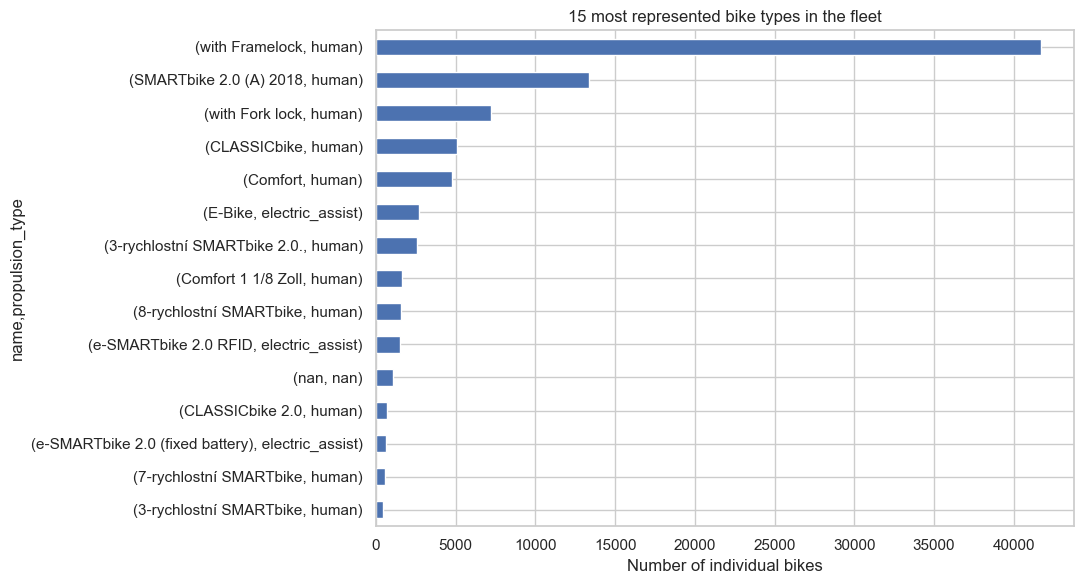

In [220]:
plt.figure(figsize=(11, 6))
bike_distribution.head(15)["individual_bikes"].sort_values().plot(kind="barh")
plt.title("15 most represented bike types in the fleet")
plt.xlabel("Number of individual bikes")
plt.tight_layout()
plt.show()

##### Bike type characteristics

In [221]:
display(types.groupby("propulsion_type", dropna=False).agg(
    type_records=("id", "count"),
    unique_names=("name", "nunique"),
    non_missing_battery=("battery_capacity", "count"),
    non_missing_range=("max_range", "count"),
    battery_values=("battery_capacity", lambda x: sorted(x.dropna().unique().tolist())),
    range_values=("max_range", lambda x: sorted(x.dropna().unique().tolist()))
))

,type_records,unique_names,non_missing_battery,non_missing_range,battery_values,range_values
propulsion_type,,,,,,
electric_assist,27,12,22,15,"[500.0, 600.0, 630.0, 690.0]",[60000.0]
human,64,34,0,0,[],[]
NaN,30,0,0,0,[],[]


In [222]:
types["form_factor"].value_counts(dropna=False).sort_index()

form_factor
bicycle          71
cargo_bicycle    19
other             1
NaN              30
Name: count, dtype: int64

In [223]:
types["rider_capacity"].value_counts(dropna=False).sort_index()

rider_capacity
1.0    70
2.0    21
NaN    30
Name: count, dtype: int64

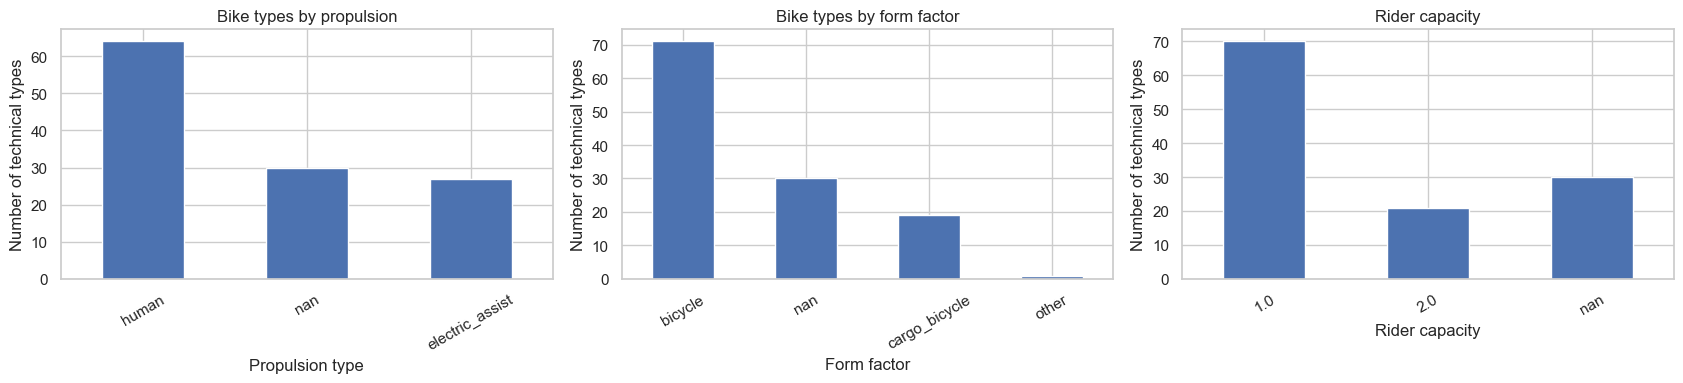

In [224]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
types["propulsion_type"].value_counts(dropna=False).plot(kind="bar", ax=axes[0], title="Bike types by propulsion")
types["form_factor"].value_counts(dropna=False).plot(kind="bar", ax=axes[1], title="Bike types by form factor")
types["rider_capacity"].value_counts(dropna=False).sort_index().plot(kind="bar", ax=axes[2], title="Rider capacity")

axes[0].set_xlabel("Propulsion type")
axes[1].set_xlabel("Form factor")
axes[2].set_xlabel("Rider capacity")

for ax in axes:
    ax.set_ylabel("Number of technical types")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [225]:
# Identifies the most reused names across different technical IDs.
name_reuse = (
    types.groupby("name", dropna=False)
    .agg(
        technical_ids=("id", "nunique"),
        propulsion_types=("propulsion_type", lambda x: x.nunique(dropna=False)),
        form_factors=("form_factor", lambda x: x.nunique(dropna=False))
    )
    .sort_values("technical_ids", ascending=False)
)
display(name_reuse.head(20))

,technical_ids,propulsion_types,form_factors
name,,,
NaN,30,1,1
Rower z fotelikiem dziecięcym,10,1,1
e-Cargobike,7,1,1
Tandem,7,1,1
Rowerek dziecięcy 6+,5,1,1
e-CARGObike,5,1,1
E-Bike,4,1,1
Cargo,4,1,1
with Framelock,4,1,1


* The 88,436 bikes span 121 types, but distribution is highly concentrated: 47% are simply named `with Framelock`. Many names describe hardware features rather than actual bike types

* 30 technical types (about 25%) lack specifications, covering 1,050 bikes (plus 253 named Unknown). We keep them as they are referenced in trip data

* Commercial names are often shared across multiple technical IDs (10 for `Rower z fotelikiem dziecięcym`), and identical bike types appear under various spellings and languages, so the raw name column requires cleaning before being used as a category

* As expected, battery capacity and range are only recorded for electric models

### 1.5 Cities

country
DE    91
PL    53
CZ    25
AT    24
HR    19
ES    16
CH    13
SI    10
GB     9
CY     2
MT     1
SK     1
SE     1
IT     1
LV     1
Name: count, dtype: int64

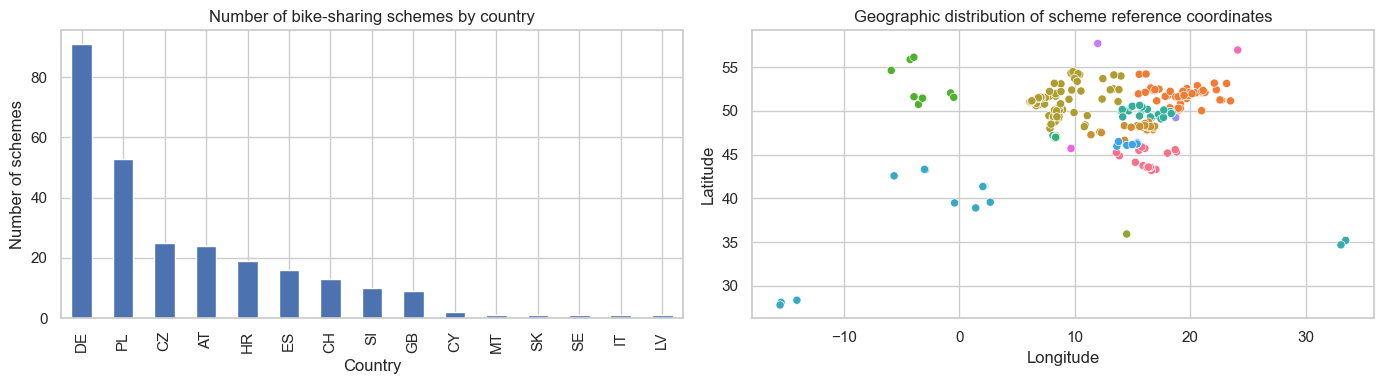

In [226]:
country_counts = city["country"].value_counts()
display(country_counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
country_counts.plot(kind="bar", ax=axes[0], title="Number of bike-sharing schemes by country", xlabel="Country", ylabel="Number of schemes")
sns.scatterplot(data=city, x="lon", y="lat", hue="country", legend=False, s=35, ax=axes[1])

axes[1].set_title("Geographic distribution of scheme reference coordinates")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")

plt.tight_layout()
plt.show()

In [227]:
print("Unique schemes:", city["id"].nunique())
print("Unique countries:", city["country"].nunique())
print("Unique time zones:", city["timezone"].nunique())
print("Coordinate pairs shared by several schemes:", int((city.groupby(["lat", "lon"]).size() > 1).sum()))

Unique schemes: 267
Unique countries: 15
Unique time zones: 9
Coordinate pairs shared by several schemes: 1


In [228]:
display(city[(city["lat"] == 51.2469) & (city["lon"] == 22.56970)])

,id,name,lat,lon,timezone,country,return_to_official_only
35,251,Lublin,51.2469,22.5697,Europe/Warsaw,PL,True
241,729,Stacje Sponsorskie Nextbike LRM,51.2469,22.5697,Europe/Warsaw,PL,True


Both records have the same approximate city-centre coordinates, but they represent separate scheme records. This is not necessarily a duplicate or an error. It could be two schemes operating in the same geographical area

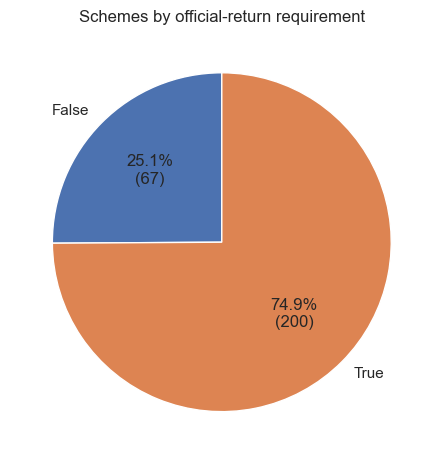

In [229]:
rto_counts = city["return_to_official_only"].value_counts().sort_index()
rto_counts.plot(
    kind="pie",
    autopct=lambda p: f"{p:.1f}%\n({int(round(p * rto_counts.sum() / 100))})",
    startangle=90,
    ylabel="",
)
plt.title("Schemes by official-return requirement")
plt.tight_layout()
plt.show()

* In total, there are 267 schemes in 15 different countries, and 9 different timezone. Germany is the country that has the more schemes (91).

* 200 out of 267 schemes (about 75%) require bikes to be returned to an official station, the other 67 allow free-floating returns. 

### 1.6 Stations and their infrastructure

In [230]:
print("Number of stations:", station["id"].nunique())

Number of stations: 2932


In [231]:
display(pd.DataFrame(station["name"].value_counts()))
display(pd.DataFrame(station["terminal_type"].value_counts()))
display(pd.DataFrame(station["place_type"].value_counts()))

,count
name,
Dworzec PKP,11
Bahnhof,9
Rathaus,5
Rynek,5
Hauptbahnhof,4
...,...
Mežaparks,1
PKP Świder,1
Rheydt Hauptbahnhof,1


,count
terminal_type,
sign,881
7inch,386
stele,329
free,276
smart_sign,162
traffic_sign,156
character,113
mmt,25
pult,14


,count
place_type,
0,2229
14,269
17,182
19,87
16,64
21,39
6,24
7,12
18,9


In [232]:
display(pd.DataFrame(station.groupby('terminal_type')['bike_racks'].count()))
display(pd.DataFrame(station.groupby(['bike_racks','terminal_type']).size()))

,bike_racks
terminal_type,
7inch,386
character,113
free,276
mmt,25
pult,14
sign,881
smart_sign,162
stele,329
terminal_sleek,3


0
bike_racks terminal_type     
0          7inch           11
           character        1
           free           229
           sign           255
           smart_sign      96
...                       ...
30         sign             1
36         sign             1
40         stele            2
56         sign             1
70         stele            2

[136 rows x 1 columns]

In [233]:
repeated_station_names = (
    station[station["name"].duplicated(keep=False)]
    .sort_values(["name", "city_id", "id"])
)

display(repeated_station_names[["id", "city_id", "name", "lon", "lat"]].head(20))

,id,city_id,name,lon,lat
293,72519774,431,Aquapark,18.102240,51.756890
1905,42613441,702,Aquapark,17.472689,49.066874
2794,16732370,523,Armii Krajowej,20.628990,52.872230
1514,10195053,562,Armii Krajowej,19.806997,51.740299
1527,10279700,564,Armii Krajowej,19.949966,52.114787
2362,29079072,220,Autobusni kolodvor,15.993288,45.804404
1014,2687297,248,Autobusni kolodvor,15.893569,43.731453
1200,687108,327,Autobusni kolodvor,15.241245,44.106828
137,61868135,747,BASF Agrarzentrum Limburgerhof,8.394231,49.413186
1140,120938456,747,BASF Agrarzentrum Limburgerhof,8.394670,49.412847


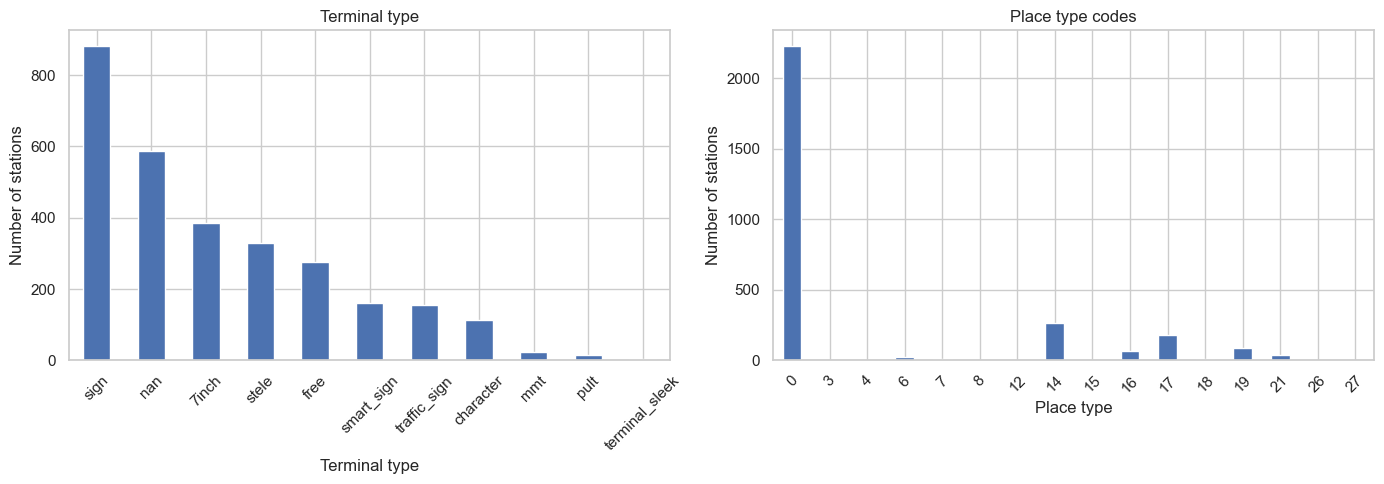

In [234]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

station["terminal_type"].value_counts(dropna=False).plot(
    kind="bar", 
    ax=axes[0], 
    title="Terminal type",
    xlabel="Terminal type"
)

station["place_type"].value_counts(dropna=False).sort_index().plot(
    kind="bar", 
    ax=axes[1], 
    title="Place type codes",
    xlabel="Place type"
)

for ax in axes:
    ax.set_ylabel("Number of stations")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [235]:
display(pd.crosstab(station["bike_racks"], station["terminal_type"]))

terminal_type,7inch,character,free,mmt,pult,sign,smart_sign,stele,terminal_sleek,traffic_sign
bike_racks,,,,,,,,,,
0,11,1,229,0,0,255,96,20,0,130
1,0,0,0,0,0,1,0,1,0,0
2,2,0,0,0,0,1,2,3,0,0
3,2,1,2,0,0,6,0,2,0,3
4,20,4,14,0,3,25,9,21,0,0
5,10,1,18,1,5,66,0,4,0,1
6,62,12,2,0,2,56,23,72,1,14
7,1,0,3,17,0,6,1,7,0,0
8,29,15,2,4,0,43,8,44,0,5


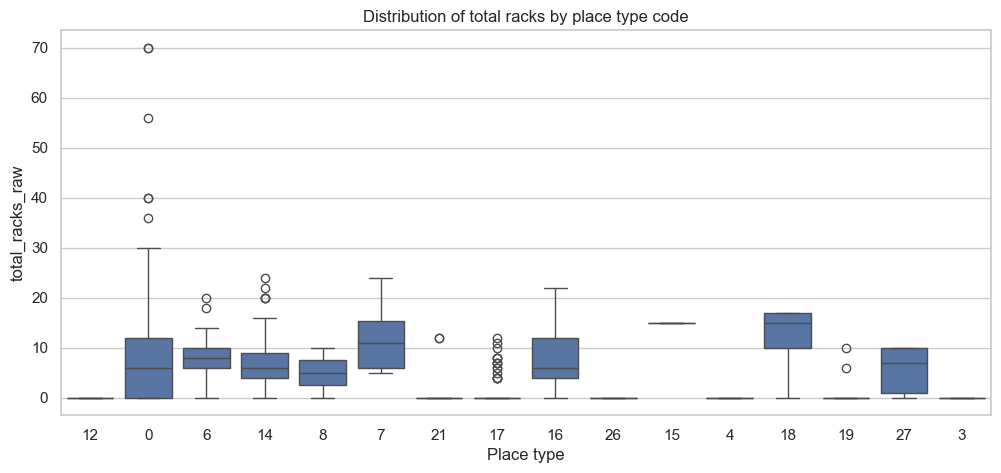

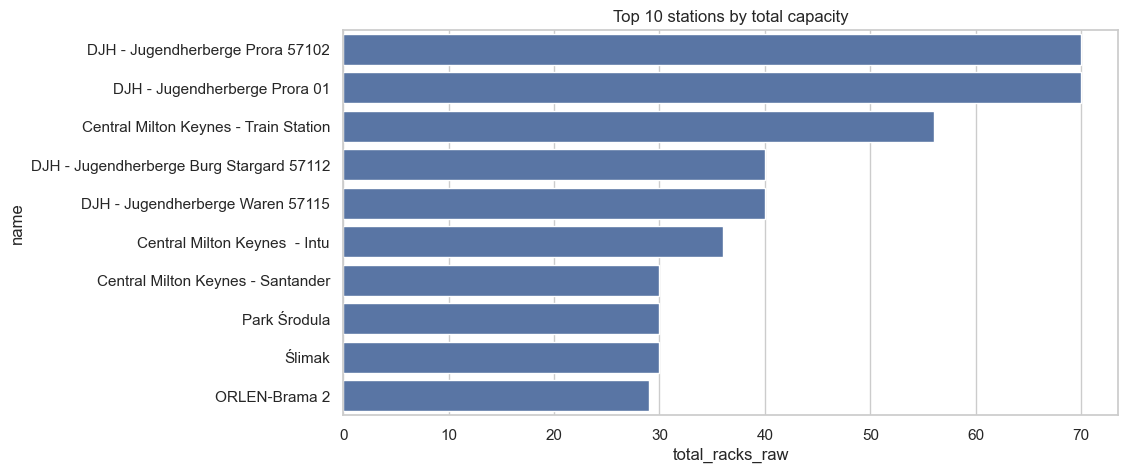

In [236]:
station["total_racks_raw"] = station["bike_racks"] + station["special_racks"]
plt.figure(figsize=(12, 5))
sns.boxplot(data=station, x=station["place_type"].astype(str), y="total_racks_raw")
plt.title("Distribution of total racks by place type code")
plt.xlabel("Place type")
plt.show()

top_stations = station.sort_values("total_racks_raw", ascending=False).head(10)
plt.figure(figsize=(10, 5))
sns.barplot(data=top_stations, x="total_racks_raw", y="name")
plt.title("Top 10 stations by total capacity")
plt.show()

##### Regular and Special Rack Capacity

In [237]:
station[['bike_racks','special_racks']]

,bike_racks,special_racks
0,0,0
1,6,0
2,15,0
3,20,0
4,6,0
...,...,...
2927,11,0
2928,10,0
2929,9,0
2930,4,0


In [238]:
station['bike_racks'].value_counts()

bike_racks
0     1220
6      276
15     263
10     257
12     249
8      162
5      115
4      102
7       47
20      37
14      37
16      28
9       19
22      18
3       17
24      14
18      14
11      12
13      10
2        8
17       5
19       5
30       3
70       2
40       2
1        2
21       2
29       1
25       1
36       1
56       1
26       1
27       1
Name: count, dtype: int64

In [239]:
print("Stations with 0 regular racks:", int((station["bike_racks"] == 0).sum()), "/", len(station))
print("Stations with negative special_racks:", int((station["special_racks"] < 0).sum()))
print("Missing coordinates:", int(station[["lon", "lat"]].isna().any(axis=1).sum()))

Stations with 0 regular racks: 1220 / 2932
Stations with negative special_racks: 32
Missing coordinates: 0


In [240]:
# Negative special_racks values
display(station[station["special_racks"] < 0])

,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,rack_locks,lon,lat,total_racks_raw
455,19772006,643,Večgeneracijski center,3282,7inch,14,6,-2,NaN,15.382405,46.380096,4
974,21257660,220,Eurospin Branimirova,2319,7inch,14,6,-2,NaN,16.043296,45.818237,4
982,60833931,220,Matrix Office Park,2359,7inch,14,10,-4,NaN,16.012638,45.796928,6
1202,16852569,327,Kolovare,2390,7inch,14,2,-1,NaN,15.235639,44.104679,1
1311,40538270,415,Poštarska ulica - Pošta,2367,7inch,14,10,-4,NaN,16.048545,45.718726,6
1326,3561904,429,Brulo,2454,7inch,14,20,-10,NaN,13.595022,45.214403,10
1329,3562085,429,Špadići,2450,7inch,14,10,-5,NaN,13.599524,45.240682,5
1439,122952272,555,Levec,5958,7inch,14,6,-2,NaN,15.220656,46.241253,4
1440,19772105,644,Mizarska cesta,3284,7inch,14,6,-2,NaN,15.424421,46.334764,4
1441,19772115,644,Gimnazija Slovenske Konjice,3285,7inch,14,6,-2,NaN,15.417756,46.337155,4


In [241]:
# Zero Rack Stations
display(station[station['bike_racks'] == 0])
print("Terminal types for stations with 0 regular racks:", station[station['bike_racks'] == 0]['terminal_type'].value_counts())

,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,rack_locks,lon,lat,total_racks_raw
0,142186362,135,BIKE 500100,0,NaN,12,0,0,NaN,7.821669,51.677449,0
10,110473405,629,FORMENTERA,3865,NaN,0,0,0,NaN,1.434906,38.912460,0
12,130175397,184,Gmünd / WK,355300,NaN,0,0,0,NaN,14.979298,48.768507,0
14,81369035,134,Wissenschaftspark Gelsenkirchen,7580,free,0,0,0,NaN,7.107439,51.497658,0
15,75832440,767,Lipůvka,48537,sign,0,0,0,NaN,16.552767,49.339050,0
...,...,...,...,...,...,...,...,...,...,...,...,...
2917,149878288,794,Borsteler Weg,2180,free,0,0,0,NaN,10.214882,53.348598,0
2920,4775113,7,Herderstraße,5187,free,0,0,0,NaN,8.233523,50.074514,0
2925,78685267,768,ZOO,49039,NaN,0,0,0,NaN,15.799026,50.435022,0
2926,104996679,768,Sylvárov,49054,NaN,0,0,0,NaN,15.814112,50.418406,0


Terminal types for stations with 0 regular racks: terminal_type
sign            255
free            229
traffic_sign    130
smart_sign       96
stele            20
7inch            11
character         1
Name: count, dtype: int64


In [242]:
# Comparing zero rack and non zero rack stations
station_status_with_capacity = station_status.merge(
    station[["id", "bike_racks", "special_racks", "terminal_type", "place_type"]],
    left_on="station_id",
    right_on="id",
    how="left",
    validate="many_to_one"
)

# New column to indicate stations with zero regular racks
station_status_with_capacity["zero_regular_racks"] = (
    station_status_with_capacity["bike_racks"] == 0
)

zero_rack_status_comparison = station_status_with_capacity.groupby("zero_regular_racks").agg(
    total_observations=("station_id", "size"),
    unique_stations_count=("station_id", "nunique"),
    avg_total_bikes_present=("bikes", "mean"),
    avg_rentable_bikes=("bikes_available_to_rent", "mean"),
    percent_time_completely_empty=("bikes_available_to_rent", lambda x: (x == 0).mean() * 100),
    avg_free_regular_racks=("free_racks", "mean"),
    avg_free_special_racks=("free_special_racks", "mean")
)

In [243]:
display(zero_rack_status_comparison)

,total_observations,unique_stations_count,avg_total_bikes_present,avg_rentable_bikes,percent_time_completely_empty,avg_free_regular_racks,avg_free_special_racks
zero_regular_racks,,,,,,,
False,2188761,1694,6.470897,6.439287,4.736150,6.69839,2.938783
True,737206,1205,5.342208,5.257677,8.567754,0.08013,0.070202


#### Station infrastructure by scheme (merge with cities)

In [244]:
station_city = station.merge(
    city, 
    left_on="city_id", 
    right_on="id", 
    how="left",
    suffixes=("_station", "_city"), 
    validate="many_to_one", 
    indicator=True
)

print(station_city["_merge"].value_counts())

_merge
both          2932
left_only        0
right_only       0
Name: count, dtype: int64


In [245]:
# Identifying stations with unmatched city IDs
unmatched_station_city = station_city.loc[
    station_city["_merge"] != "both",
    ["id_station", "city_id", "name_station"]
]
display(unmatched_station_city)

,id_station,city_id,name_station


,,number_of_stations
city_id,name_city,
251,Lublin,121
817,Mobic,121
176,Usedom,89
680,Pardubice,61
206,Nicosia,60
...,...,...
647,Graben,2
831,Wolsztyn,2
741,Općina Klis,2


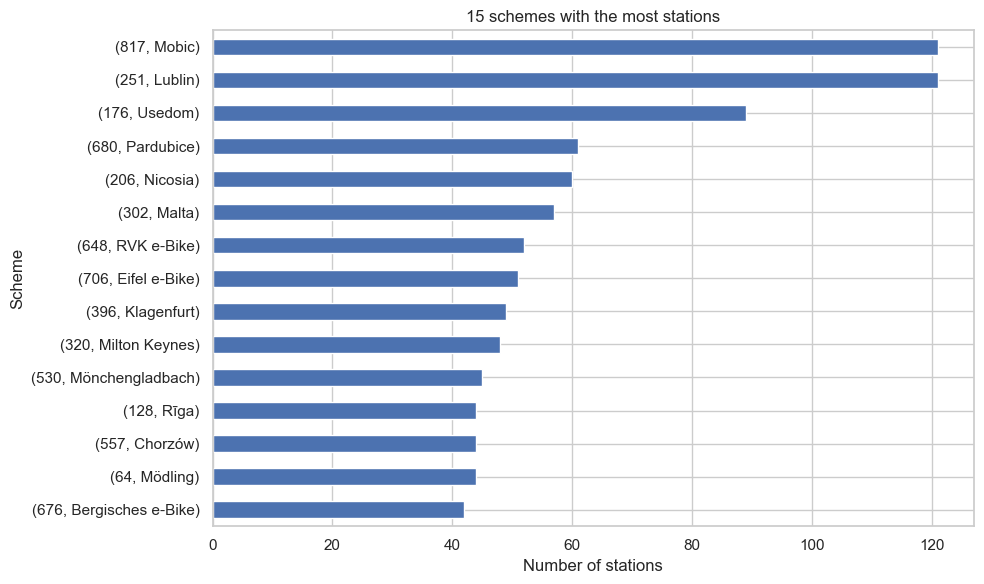

In [246]:
# Number of stations per scheme
stations_per_city = (
    station_city.groupby(['city_id', 'name_city'])
    .agg(number_of_stations=('id_station', 'count'))
    .sort_values('number_of_stations', ascending=False)
)

display(stations_per_city)

plt.figure(figsize=(10, 6))
stations_per_city.head(15)["number_of_stations"].sort_values().plot(kind="barh")
plt.title("15 schemes with the most stations")
plt.xlabel("Number of stations")
plt.ylabel("Scheme")
plt.tight_layout()
plt.show()

In [247]:
# Capacity per scheme
capacity_per_city = (
    station_city.groupby(["city_id", "name_city"])
    .agg(
        number_of_stations=("id_station", "nunique"),
        total_regular_racks=("bike_racks", "sum"),
        total_special_racks_raw=("special_racks", "sum"),
        mean_regular_racks=("bike_racks", "mean"),
        median_regular_racks=("bike_racks", "median"),
        stations_with_negative_special_racks=("special_racks", lambda x: (x < 0).sum())
    )
    .sort_values("total_regular_racks", ascending=False)
)
display(capacity_per_city.head(20))

,,number_of_stations,total_regular_racks,total_special_racks_raw,mean_regular_racks,median_regular_racks,stations_with_negative_special_racks
city_id,name_city,,,,,,
251,Lublin,121,1256,0,10.380165,15.0,0
176,Usedom,89,818,0,9.191011,8.0,0
557,Chorzów,44,655,0,14.886364,15.0,0
775,MV-Rad,38,567,0,14.921053,10.0,0
320,Milton Keynes,48,545,0,11.354167,8.0,0
302,Malta,57,437,0,7.666667,6.0,0
497,Sosnowiec,25,412,0,16.480000,12.0,0
396,Klagenfurt,49,382,0,7.795918,8.0,0
639,Orlen Płock,25,375,0,15.000000,15.0,0


In [248]:
# Average station capacity per scheme
station_city.groupby(['city_id', 'name_city']).agg(
    average_regular_racks=('bike_racks', 'mean'),
    median_regular_racks=('bike_racks', 'median'),
    average_special_racks=('special_racks', 'mean')
).sort_values('average_regular_racks', ascending=False)

,,average_regular_racks,median_regular_racks,average_special_racks
city_id,name_city,,,
550,Marki,22.000000,22.0,0.0
853,Sant Just Desvern,20.000000,21.0,0.0
856,Sant Boi de Llobregat,20.000000,20.0,0.0
848,Esplugues de Llobregat,19.636364,20.0,0.0
446,Szamotuły,17.714286,18.0,0.0
...,...,...,...,...
767,Kuřim,0.000000,0.0,0.0
752,Hlučín,0.000000,0.0,0.0
747,Limburgerhof,0.000000,0.0,0.0


In [249]:
# Groups stations by city to compute the proportion of zero-rack stations
# Sorted by highest percentage

zero_rack_analysis = (
    station_city.assign(
        zero_rack=station_city['bike_racks'].eq(0)
    )
    .groupby(['city_id', 'name_city'])
    .agg(
        total_stations=('id_station', 'count'),
        zero_rack_stations=('zero_rack', 'sum')
    )
)

zero_rack_analysis['zero_rack_percentage'] = (
    100 * zero_rack_analysis['zero_rack_stations']
    / zero_rack_analysis['total_stations']
)

zero_rack_analysis.sort_values('zero_rack_percentage', ascending=False)

,,total_stations,zero_rack_stations,zero_rack_percentage
city_id,name_city,,,
23,Neusiedler See,29,29,100.0
88,Sursee Plus,41,41,100.0
64,Mödling,44,44,100.0
165,Herzogenburg,2,2,100.0
170,Marchfeld,3,3,100.0
...,...,...,...,...
808,Geilenkirchen,4,0,0.0
831,Wolsztyn,2,0,0.0
848,Esplugues de Llobregat,11,0,0.0


* 1,220 of 2,932 stations (41.6%) have zero regular racks. They are probably virtual free-floating zones (as confirmed by their terminal types which are mostly `free` or `sign`)

* The proportion of these stations varies significantly across cities: some networks have zero physical racks, while others are entirely dock-based.

* 32 stations have a negative `special_racks`, all of which feature a 7-inch terminal type

### 1.7 Station status: consistency

In [250]:
maintenance_analysis = station_status.groupby('maintenance').agg(
    observations=('station_id', 'size'),
    mean_bikes=('bikes', 'mean'),
    mean_booked=('booked_bikes', 'mean'),
    mean_available=('bikes_available_to_rent', 'mean'),
    zero_available=(
        'bikes_available_to_rent',
        lambda x: (x == 0).mean() * 100
    )
)

maintenance_analysis

,observations,mean_bikes,mean_booked,mean_available,zero_available
maintenance,,,,,
False,2795425,6.188272,0.047497,6.141872,5.772074
True,130542,6.149025,0.013919,6.135251,4.190988


In [251]:
raw_difference = station_status["bikes"] - station_status["booked_bikes"]
clamped_expected = raw_difference.clip(lower=0)

raw_match = station_status["bikes_available_to_rent"].eq(raw_difference)
clamped_match = station_status["bikes_available_to_rent"].eq(clamped_expected)

formula_comparison = pd.DataFrame({
    "comparison": ["bikes - booked_bikes", "max(bikes - booked_bikes, 0)"],
    "matching_rows": [int(raw_match.sum()), int(clamped_match.sum())],
    "non_matching_rows": [int((~raw_match).sum()), int((~clamped_match).sum())],
    "match_percent": [raw_match.mean() * 100, clamped_match.mean() * 100]
})
display(formula_comparison)

,comparison,matching_rows,non_matching_rows,match_percent
0,bikes - booked_bikes,2923631,2336,99.920163
1,"max(bikes - booked_bikes, 0)",2925902,65,99.997779


In [252]:
remaining_formula_cases = station_status.loc[
    ~clamped_match,
    ["station_id", "time", "bikes", "booked_bikes",
     "bikes_available_to_rent", "maintenance",
     "free_racks", "free_special_racks"]
]
display(remaining_formula_cases)

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,maintenance,free_racks,free_special_racks
1419140,2591849,1.678257e+09,5,1,5,False,0,0
1419141,50458,1.678257e+09,5,3,4,False,5,0
1419146,54635,1.678257e+09,5,2,5,False,0,0
1419153,54635,1.678257e+09,5,3,5,False,0,0
1419174,54635,1.678257e+09,5,4,4,False,0,0
...,...,...,...,...,...,...,...,...
1422937,142154767,1.678302e+09,5,1,5,False,6,0
1423447,142154767,1.678314e+09,5,1,5,False,17,0
1423684,51003977,1.678336e+09,5,1,5,False,4,3
1423687,51003977,1.678336e+09,5,1,5,False,4,4


In [253]:
negative_bookings = station_status[
    station_status['booked_bikes'] < 0
]

print("Rows with negative booked_bikes:", len(negative_bookings))
negative_bookings.groupby('maintenance').size()

Rows with negative booked_bikes: 160


maintenance
False    154
True       6
dtype: int64

In [254]:
display(negative_bookings["booked_bikes"].value_counts().sort_index())

booked_bikes
-4      5
-3      2
-2     33
-1    120
Name: count, dtype: int64

In [255]:
status_capacity = station_status.merge(
    station[['id', 'bike_racks', 'special_racks']],
    left_on='station_id',
    right_on='id',
    how='left',
    validate='many_to_one'
)

status_capacity['declared_capacity_raw'] = (
    status_capacity['bike_racks']
    + status_capacity['special_racks']
)

status_capacity['observed_occupied_and_free'] = (
    status_capacity['bikes']
    + status_capacity['free_racks']
    + status_capacity['free_special_racks']
)

status_capacity["capacity_difference_raw"] = (
    status_capacity["declared_capacity_raw"] -
    status_capacity["observed_occupied_and_free"]
)

status_capacity['capacity_difference_raw'].describe()

count    2.925967e+06
mean    -3.780645e+00
std      6.810545e+00
min     -1.890000e+02
25%     -6.000000e+00
50%     -2.000000e+00
75%      0.000000e+00
max      2.900000e+01
Name: capacity_difference_raw, dtype: float64

In [256]:
print("Unmatched station metadata rows:", int(status_capacity["id"].isna().sum()))
print("Stations with negative special_racks:", int((station["special_racks"] < 0).sum()))
print("Status rows with negative special-rack metadata:",
      int((status_capacity["special_racks"] < 0).sum()))
display(status_capacity["capacity_difference_raw"].describe())
display(status_capacity["capacity_difference_raw"].value_counts().head(20))
del status_capacity

Unmatched station metadata rows: 0
Stations with negative special_racks: 32
Status rows with negative special-rack metadata: 22194


count    2.925967e+06
mean    -3.780645e+00
std      6.810545e+00
min     -1.890000e+02
25%     -6.000000e+00
50%     -2.000000e+00
75%      0.000000e+00
max      2.900000e+01
Name: capacity_difference_raw, dtype: float64

capacity_difference_raw
 0     886042
-2     194536
-3     179426
-1     175245
-4     172475
-5     157170
-6     126727
-7     113082
-8     101856
 1      92644
-9      85651
-10     74567
-11     63820
 2      62241
-12     54362
-13     44853
-14     35032
 4      34852
 3      33810
-15     27613
Name: count, dtype: int64

##### Correlation between station status measurements

In [257]:
status_numeric_columns = [
    "bikes", "booked_bikes", "bikes_available_to_rent",
    "free_racks", "free_special_racks"
]
status_correlations = station_status[status_numeric_columns].corr()
display(status_correlations)

,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks
bikes,1.000000,0.010393,0.997925,-0.104465,0.057923
booked_bikes,0.010393,1.000000,-0.053644,-0.018085,-0.044238
bikes_available_to_rent,0.997925,-0.053644,1.000000,-0.103170,0.060706
free_racks,-0.104465,-0.018085,-0.103170,1.000000,0.587193
free_special_racks,0.057923,-0.044238,0.060706,0.587193,1.000000


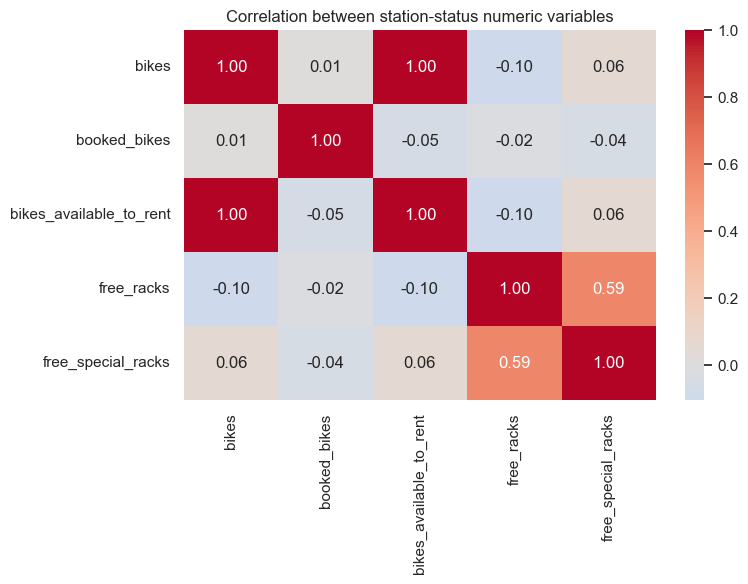

In [258]:
plt.figure(figsize=(8, 6))
sns.heatmap(status_correlations, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between station-status numeric variables")
plt.tight_layout()
plt.show()

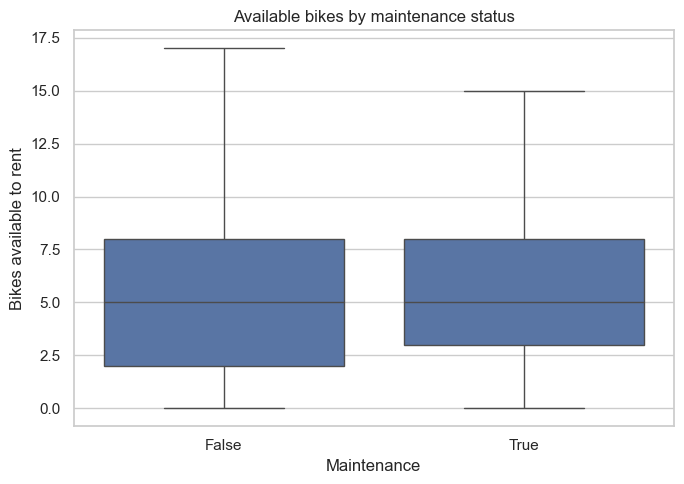

In [259]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=station_status, x="maintenance",
            y="bikes_available_to_rent", showfliers=False)
plt.title("Available bikes by maintenance status")
plt.xlabel("Maintenance")
plt.ylabel("Bikes available to rent")
plt.tight_layout()
plt.show()

### 1.8 Station status: temporal structure

In [260]:
station_status['datetime'] = pd.to_datetime(
    station_status['time'],
    unit='s',
    utc=True
)

print("Period:", station_status['datetime'].min(), "to", station_status['datetime'].max())
print("Time span:", station_status['datetime'].max() - station_status['datetime'].min())
print("Unique stations in status:", station_status['station_id'].nunique())
print("Duplicate station-time rows:", station_status.duplicated(["station_id", "time"]).sum())

Period: 2022-08-26 14:48:01+00:00 to 2023-07-15 21:59:01+00:00
Time span: 323 days 07:11:00
Unique stations in status: 2899
Duplicate station-time rows: 0


In [261]:
status = station_status.sort_values(['station_id', 'time']).copy()
status['gap_min'] = status.groupby('station_id')['time'].diff()/60
status['gap_min'].describe()

count    2.923068e+06
mean     3.665869e+02
std      3.416895e+03
min      8.000000e-01
25%      4.000000e+00
50%      2.800000e+01
75%      1.580000e+02
max      4.147360e+05
Name: gap_min, dtype: float64

In [262]:
station_frequency = status.groupby('station_id').agg(
    observations=('time', 'count'),
    median_interval=('gap_min', 'median'),
    mean_interval=('gap_min', 'mean')
)

station_frequency.describe().T

,count,mean,std,min,25%,50%,75%,max
observations,2899.0,1009.302173,1678.189339,1.0,159.000000,427.000000,1099.500000,16643.0
median_interval,2892.0,543.201922,2511.697487,1.0,57.500000,155.750000,398.750000,80120.0
mean_interval,2892.0,2029.832845,4496.716904,1.0,330.237663,793.208309,2024.189945,80120.0


In [263]:
print("Number of duplicates:",status.duplicated(subset=['station_id', 'time']).sum())

Number of duplicates: 0


C:\Users\dgtrh\AppData\Local\Temp\ipykernel_21928\1848486113.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  station_status["month"] = station_status["datetime"].dt.to_period("M").astype(str)


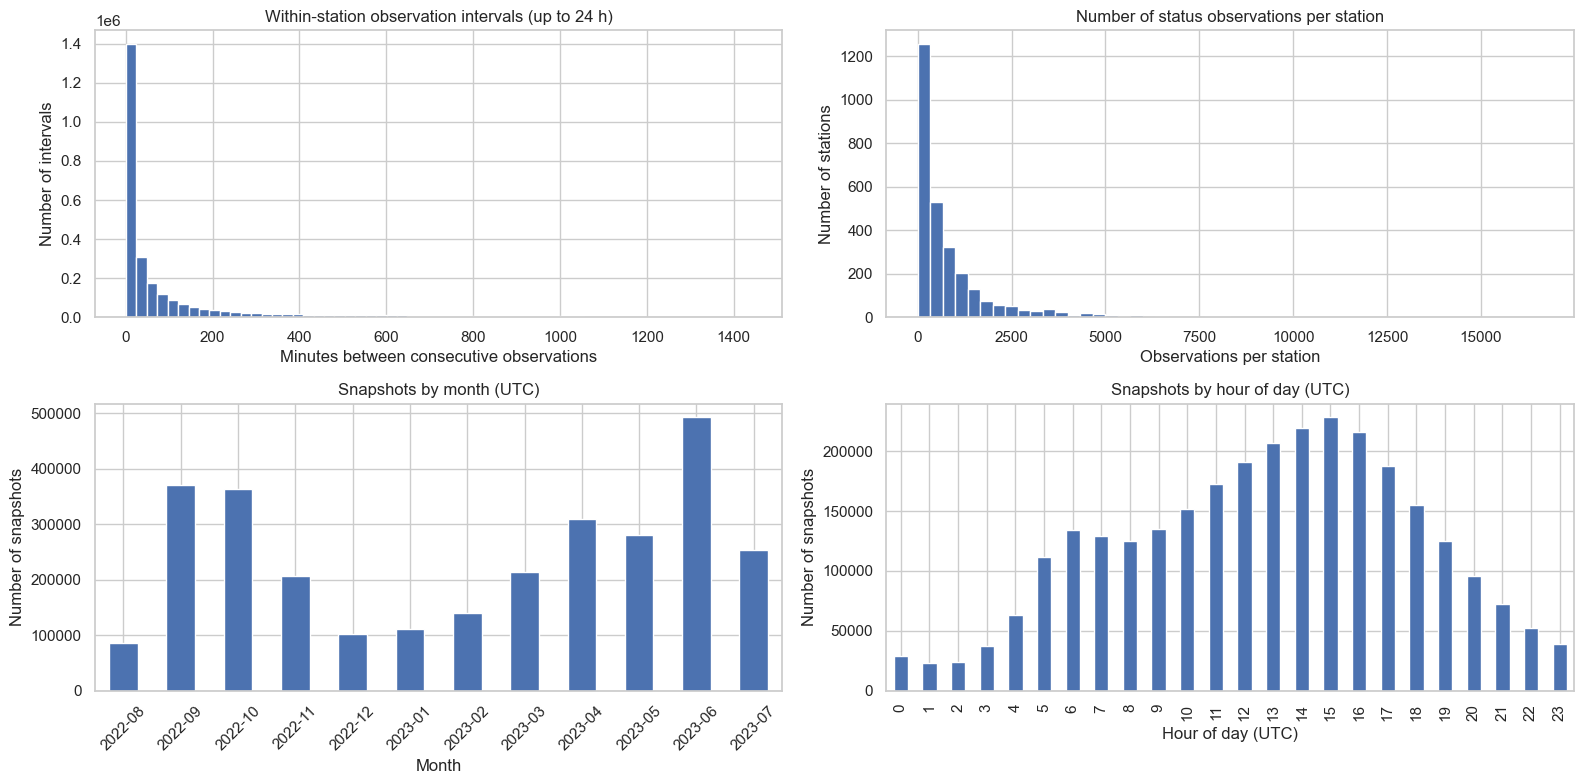

In [264]:
intervals = status["gap_min"].dropna()

station_status["month"] = station_status["datetime"].dt.to_period("M").astype(str)
station_status["hour_utc"] = station_status["datetime"].dt.hour
station_status["weekday_utc"] = station_status["datetime"].dt.day_name()

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
axes = axes.flatten()

axes[0].hist(intervals[intervals <= 24 * 60], bins=60)
axes[0].set_title("Within-station observation intervals (up to 24 h)")
axes[0].set_xlabel("Minutes between consecutive observations")
axes[0].set_ylabel("Number of intervals")

axes[1].hist(station_frequency["observations"], bins=50)
axes[1].set_title("Number of status observations per station")
axes[1].set_xlabel("Observations per station")
axes[1].set_ylabel("Number of stations")

station_status.groupby("month").size().plot(
    kind="bar", ax=axes[2], title="Snapshots by month (UTC)"
)
axes[2].set_xlabel("Month")
axes[2].set_ylabel("Number of snapshots")
axes[2].tick_params(axis="x", rotation=45)

station_status.groupby("hour_utc").size().plot(
    kind="bar", ax=axes[3], title="Snapshots by hour of day (UTC)"
)
axes[3].set_xlabel("Hour of day (UTC)")
axes[3].set_ylabel("Number of snapshots")

plt.tight_layout()
plt.show()

### 1.9 Trips

In [265]:
trip_validity = pd.Series({
    "duration_nonpositive": (trips["duration"] <= 0).sum(),
    "distance_nonpositive": (trips["distance"] <= 0).sum(),
    "invalid_start_longitude": (~trips["lon_start"].between(-180, 180)).sum(),
    "invalid_end_longitude": (~trips["lon_end"].between(-180, 180)).sum(),
    "invalid_start_latitude": (~trips["lat_start"].between(-90, 90)).sum(),
    "invalid_end_latitude": (~trips["lat_end"].between(-90, 90)).sum()
}, name="count")
display(trip_validity)

duration_nonpositive       0
distance_nonpositive       0
invalid_start_longitude    0
invalid_end_longitude      0
invalid_start_latitude     0
invalid_end_latitude       0
Name: count, dtype: int64

In [266]:
display(trips[["duration", "distance"]].corr())

,duration,distance
duration,1.000000,0.391023
distance,0.391023,1.000000


In [267]:
trip_summary = trips[["duration", "distance"]].describe(
    percentiles=[.5, .75, .9, .95, .99]
).T
display(trip_summary)

,count,mean,std,min,50%,75%,90%,95%,99%,max
duration,1161376.0,1256.241229,1980.837946,121.000000,720.000000,1200.000000,2340.000000,3960.000000,10200.00000,28740.000000
distance,1161376.0,1791.773844,1495.190508,50.013649,1346.710991,2238.540454,3415.328448,4344.718527,7418.18874,19999.457592


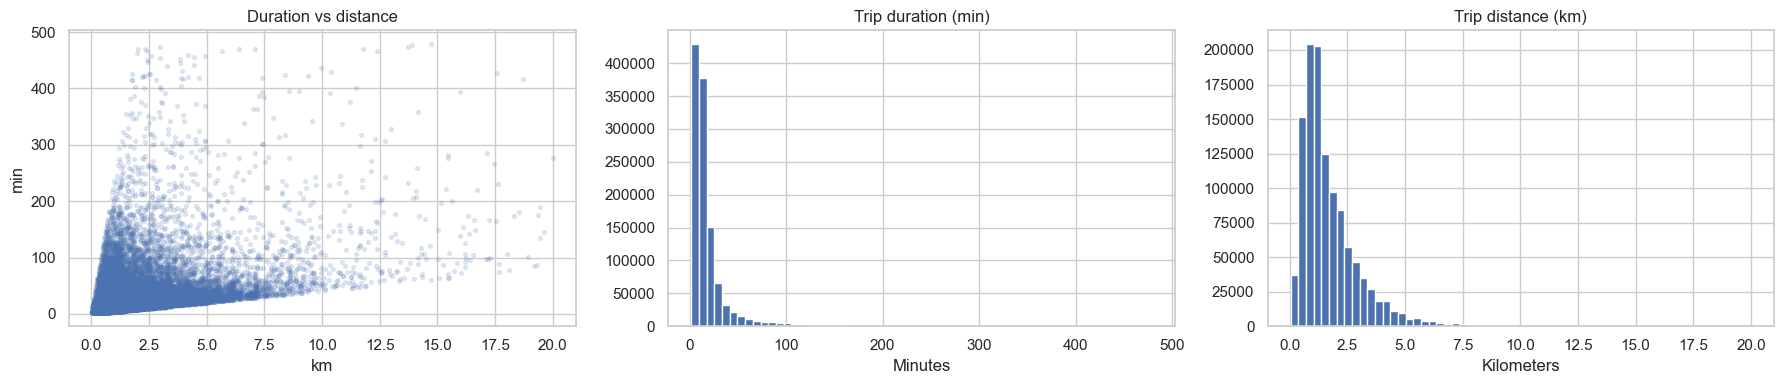

In [268]:
sample = trips.sample(n=min(50000, len(trips)), random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].scatter(sample["distance"] / 1000, sample["duration"] / 60, alpha=0.15, s=8)
axes[0].set_title("Duration vs distance")
axes[0].set_xlabel("km")
axes[0].set_ylabel("min")

axes[1].hist(trips["duration"] / 60, bins=60)
axes[1].set_title("Trip duration (min)")
axes[1].set_xlabel("Minutes")

axes[2].hist(trips["distance"] / 1000, bins=60)
axes[2].set_title("Trip distance (km)")
axes[2].set_xlabel("Kilometers")

plt.tight_layout()
plt.show()

In [269]:
trip_profile = (
    trips.merge(
        bike[["id", "bike_type_id"]].rename(columns={"id": "bike_id"}), 
        on="bike_id",
        how="left", 
        validate="many_to_one"
    ).merge(
        types[["id", "propulsion_type"]].rename(columns={"id": "bike_type_id"}), 
        on="bike_type_id", 
        how="left", 
        validate="many_to_one"
    )
)

battery_missing_by_propulsion = trip_profile.groupby("propulsion_type", dropna=False).agg(
    trips=("bike_id", "size"),
    missing_battery_start=("battery_start", lambda x: x.isna().mean() * 100),
    missing_battery_end=("battery_end", lambda x: x.isna().mean() * 100),
    median_battery_start=("battery_start", "median"),
    median_battery_end=("battery_end", "median")
)
display(battery_missing_by_propulsion)

,trips,missing_battery_start,missing_battery_end,median_battery_start,median_battery_end
propulsion_type,,,,,
electric_assist,180091,6.586115,6.52559,89.0,83.0
human,978939,99.969150,99.96915,0.0,0.0
NaN,2346,100.000000,100.00000,NaN,NaN


In [270]:
trip_profile["start_station_missing"] = trip_profile["station_id_start"].isna()
trip_profile["end_station_missing"] = trip_profile["station_id_end"].isna()

In [271]:
free_floating_by_propulsion = trip_profile.groupby(
    "propulsion_type", dropna=False
).agg(
    trips=("bike_id", "size"),
    missing_start_station_percent=("start_station_missing", "mean"),
    missing_end_station_percent=("end_station_missing", "mean")
) * 1
free_floating_by_propulsion[[
    "missing_start_station_percent", "missing_end_station_percent"
]] *= 100
display(free_floating_by_propulsion)

,trips,missing_start_station_percent,missing_end_station_percent
propulsion_type,,,
electric_assist,180091,4.906408,5.995858
human,978939,8.208070,11.346468
NaN,2346,1.150895,1.321398


In [272]:
trip_city = trips.merge(
    city[["id", "name", "country"]],
    left_on="city_id",
    right_on="id",
    how="left",
    validate="many_to_one",
    suffixes=("_trip", "_scheme")
)

trip_city["start_station_missing"] = trip_city["station_id_start"].isna()
trip_city["end_station_missing"] = trip_city["station_id_end"].isna()

free_floating_by_scheme = trip_city.groupby(
    ["city_id", "name", "country"], dropna=False
).agg(
    trips=("time_start", "size"),
    missing_start_station_percent=("start_station_missing", "mean"),
    missing_end_station_percent=("end_station_missing", "mean")
)

free_floating_by_scheme[[
    "missing_start_station_percent", "missing_end_station_percent"
]] *= 100
display(free_floating_by_scheme.sort_values("trips", ascending=False).head(20))

,,,trips,missing_start_station_percent,missing_end_station_percent
city_id,name,country,,,
848,Esplugues de Llobregat,ES,29661,0.000000,0.003371
592,Walldorf,DE,28458,62.896198,67.288636
88,Sursee Plus,CH,28230,9.029401,14.243712
530,Mönchengladbach,DE,27232,4.615893,11.262485
817,Mobic,DE,27073,21.161305,23.647176
856,Sant Boi de Llobregat,ES,26840,0.003726,0.029806
749,Getxo,ES,25874,3.416557,4.804050
496,Koszalin,PL,25160,1.693164,2.062798
251,Lublin,PL,24785,1.468630,2.453097


## 2. Data Preparation

### 2.1 Bike types

In [273]:
types_c = types.copy()
types_c["propulsion_type"] = types_c["propulsion_type"].replace({"electric_assist": "electric"})
types_c["form_factor"] = types_c["form_factor"].replace({"bicycle": "regular", "cargo_bicycle": "cargo"})

# electric types with missing battery/range: mean of electric types with the same form factor
battery_cols = ["max_range", "battery_capacity"]
is_electric = types_c["propulsion_type"] == "electric"
for form in ["regular", "cargo"]:
    m = is_electric & (types_c["form_factor"] == form)
    types_c.loc[m, battery_cols] = types_c.loc[m, battery_cols].fillna(types_c.loc[m, battery_cols].mean())

# remaining gaps: unknown types (kept: referenced by bikes) and human-powered bikes
string_cols = ["vehicle_image", "name", "description", "form_factor", "propulsion_type"]
numeric_cols = ["rider_capacity", "max_range", "battery_capacity"]
types_c[string_cols] = types_c[string_cols].fillna("Unknown")
types_c[numeric_cols] = types_c[numeric_cols].fillna(0)

print("Missing values left:", int(types_c.isna().sum().sum()))
print(types_c["propulsion_type"].value_counts().to_dict(), types_c["form_factor"].value_counts().to_dict())

Missing values left: 0
{'human': 64, 'Unknown': 30, 'electric': 27} {'regular': 71, 'Unknown': 30, 'cargo': 19, 'other': 1}


#### Cleaning the bike-type names

The 46 commercial names represent bike types under various spellings and languages. They are normalized using prioritized keyword rules (most specific first). Names describing only locks or hardware generations (for example `with Framelock`) are classified as standard city bikes. 

In [274]:
def clean_bike_type_name(name):
    
    if pd.isna(name) or str(name).strip().lower() in {"", "unknown", "nan"}:
        return "Unknown"
    
    n = re.sub(r"\s+", " ", str(name)).strip().lower()
    rules = [
        ("E-cargo bike",         r"^e-?cargo"),
        ("Cargo bike",           r"cargo"),
        ("Tandem",               r"tandem"),
        ("Handbike",             r"handbike"),
        ("Tricycle",             r"tr[oó]jko[lł]owy|tricycle"),
        ("Bike with child seat", r"fotelik|child|sjedalica"),
        ("Kids bike",            r"kinder|rowerek"),
        ("E-bike",               r"^e-?bike|^e-?smartbike|^e-?classicbike|elektri"),
        ("City bike",            r"smartbike|classic|comfort|tourenfahrrad|usedomrad|wa[łl]em|kardan|framelock|fork lock"),
    ]

    for label, pattern in rules:
        if re.search(pattern, n):
            return label
    return "Other"

In [275]:
types_c["bike_type_group"] = types_c["name"].map(clean_bike_type_name)
print("Names mapped to 'Other' (to be reviewed):", sorted(types_c.loc[types_c["bike_type_group"] == "Other", "name"].unique()))
types_c["bike_type_group"].value_counts(dropna=False).sort_index()

Names mapped to 'Other' (to be reviewed): []


bike_type_group
Bike with child seat    13
Cargo bike               7
City bike               27
E-bike                  15
E-cargo bike            12
Handbike                 1
Kids bike                7
Tandem                   7
Tricycle                 1
Unknown                 31
Name: count, dtype: int64

In [276]:
# Name with bike_type_group mapping
mapping = (types_c.groupby(["bike_type_group", "name"])
           .agg(technical_ids=("id", "count"), bikes=("id", lambda s: int(bike["bike_type_id"].isin(s).sum())))
           .sort_values(["bike_type_group", "bikes"], ascending=[True, False]))
display(mapping)

technical_ids  bikes
bike_type_group      name                                                 
Bike with child seat + Children's seat                            1    200
                     Rower z fotelikiem dziecięcym               10    168
                     Bike with child seat                         1     65
                     Dječja sjedalica                             1     26
Cargo bike           CARGObike                                    2     94
                     Cargo                                        4     53
                     CARGObike (3 wheels)                         1     16
City bike            with Framelock                               4  41691
                     SMARTbike 2.0 (A) 2018                       1  13375
                     with Fork lock                               1   7227
                     CLASSICbike                                  1   5108
                     Comfort                                      1   4756
                     3-rychlostní SMARTbike 2.0.                  3   2547
                     Comfort 1 1/8 Zoll                           1   1607
                     8-rychlostní SMARTbike                       2   1558
                     CLASSICbike 2.0                              1    725
                     7-rychlostní SMARTbike                       2    600
                     3-rychlostní SMARTbike                       1    451
                     8-rychlostní SMARTbike 2.0.                  1    297
                     28 Zoll - Tourenfahrrad                      1    197
                     UsedomRad                                    1    184
                     Classic                                      1     75
                     UsedomRad Classic                            1     43
                     7-rychlostní SMARTbike 2.0.                  1     42
                     Z wałem kardana                              1     30
                     26 Zoll - Tourenfahrrad                      1      8
                     Smartbike 2.0 (B) 2019                       1      1
E-bike               E-Bike                                       4   2729
                     e-SMARTbike 2.0 RFID                         1   1487
                     e-SMARTbike 2.0 (fixed battery)              1    661
                     e-SMARTbike 2.0.                             3    334
                     E-CLASSICbike SWAP                           1    229
                     e-SMARTbike 2.0 with RFID                    1    126
                     e-SMARTbike 1.0                              1     79
                     Elektricno kolo                              1     60
                     ebike [električni bicikl]                    1     44
                     e-Bike "LaBigi"                              1     11
E-cargo bike         e-CARGObike                                  5     75
                     e-Cargobike                                  7     21
Handbike             Handbike                                     1      1
Kids bike            Rowerek dziecięcy 6+                         5     83
                     24 Zoll - Kinderfahrrad                      1      6
                     20 Zoll - Kinderfahrrad                      1      1
Tandem               Tandem                                       7     38
Tricycle             Rower Trójkołowy                             1      4
Unknown              Unknown                                     31   1303

In [277]:
# Summary with bike_type_group
display(types_c.groupby("bike_type_group").agg(
    raw_names=("name", "nunique"), technical_ids=("id", "count"),
    bikes=("id", lambda s: int(bike["bike_type_id"].isin(s).sum()))).sort_values("bikes", ascending=False))

,raw_names,technical_ids,bikes
bike_type_group,,,
City bike,20,27,80522
E-bike,10,15,5760
Unknown,1,31,1303
Bike with child seat,4,13,459
Cargo bike,3,7,163
E-cargo bike,2,12,96
Kids bike,3,7,90
Tandem,1,7,38
Tricycle,1,1,4


In [278]:
# Checking the relationship between bike_type_group and propulsion_type
display(pd.crosstab(types_c["bike_type_group"], types_c["propulsion_type"]))

propulsion_type,Unknown,electric,human
bike_type_group,,,
Bike with child seat,0,0,13
Cargo bike,0,0,7
City bike,0,0,27
E-bike,0,15,0
E-cargo bike,0,12,0
Handbike,0,0,1
Kids bike,0,0,7
Tandem,0,0,7
Tricycle,0,0,1


* The raw names collapse into 10 groups: *City bike*, *E-bike*, *Cargo bike*, *E-cargo bike*, *Bike with child seat*, *Kids bike*, *Tandem*, *Tricycle*, *Handbike* and *Unknown*. No name falls into *Other*, so the rules cover every name present in the data 

* The cross-table with `propulsion_type` is a consistency check: the *E-bike* and *E-cargo bike* groups should be electric and the *City bike* group human-powered. 

### 2.2 Stations

In [279]:
station_c = station.drop(columns=["rack_locks", "total_racks_raw"], errors="ignore").copy()

station_c["negative_special_racks_flag"] = (station_c["special_racks"] < 0).astype(int)
station_c["zero_regular_racks_flag"] = (station_c["bike_racks"] == 0).astype(int)

station_c["terminal_type"] = station_c["terminal_type"].fillna("Unknown")

station_c = station_c.merge(
    city[["id", "name", "country", "timezone", "return_to_official_only"]].rename(
        columns={"id": "city_id", "name": "scheme"}),
    on="city_id", 
    how="left", 
    validate="many_to_one"
)

station_c["return_to_official_only"] = station_c["return_to_official_only"].astype(int)
print("Shape:", station_c.shape)
print("Missing values:", int(station_c[["terminal_type", "country", "timezone"]].isna().sum().sum()))

Shape: (2932, 16)
Missing values: 0


### 2.3 Station status

In [280]:
STATION_INFO = station_c.set_index("id")

# Cleans raw station status data, adds UTC time features (hour, weekend), 
# and computes occupancy metrics like fill rate, empty, and full flags.
def prepare_status(raw):
    
    s = raw.drop_duplicates(["station_id", "time"]).copy()

    s = s[s["station_id"].isin(STATION_INFO.index)].reset_index(drop=True)
    
    s["datetime"] = pd.to_datetime(s["time"], unit="s", utc=True).astype("datetime64[ns, UTC]")
    s["hour_utc"] = s["datetime"].dt.hour
    s["day_of_week_utc"] = s["datetime"].dt.dayofweek
    
    s["maintenance"] = s["maintenance"].astype(int)
    
    return s

status = prepare_status(station_status)
print(status.shape)
print("Period (UTC):", status["datetime"].min(), "->", status["datetime"].max())
status.head()

(2925967, 13)
Period (UTC): 2022-08-26 14:48:01+00:00 -> 2023-07-15 21:59:01+00:00


,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance,datetime,month,hour_utc,weekday_utc,day_of_week_utc
0,101896428,1.661530e+09,2,0,2,0,0,0,2022-08-26 16:14:01+00:00,2022-08,16,Friday,4
1,54643,1.661531e+09,1,0,1,0,0,0,2022-08-26 16:15:01+00:00,2022-08,16,Friday,4
2,6201611,1.661531e+09,3,0,3,0,0,0,2022-08-26 16:15:01+00:00,2022-08,16,Friday,4
3,294346,1.661531e+09,8,0,8,0,0,0,2022-08-26 16:15:01+00:00,2022-08,16,Friday,4
4,781866,1.661531e+09,1,1,0,5,0,0,2022-08-26 16:15:01+00:00,2022-08,16,Friday,4


### 2.4 Trips

In [281]:
def clean_trips(trips, bike, types_c, city):
    t = trips.copy()

    # Types
    t["station_id_start"] = t["station_id_start"].astype("Int64")
    t["station_id_end"] = t["station_id_end"].astype("Int64")

    t["time_start_dt"] = pd.to_datetime(t["time_start"], unit="s", utc=True)
    t["duration_min"] = t["duration"] / 60
    t["distance_km"] = t["distance"] / 1000

    t["free_start"] = t["station_id_start"].isna().astype(int)
    t["free_end"] = t["station_id_end"].isna().astype(int)

    t["hour_utc"] = t["time_start_dt"].dt.hour
    t["day_of_week_utc"] = t["time_start_dt"].dt.dayofweek
    t["time_end_dt"] = t["time_start_dt"] + pd.to_timedelta(t["duration_min"], unit="min")

    # Merges trips with bike, types, and city 
    t = (
        t.merge(
            bike[["id", "bike_type_id"]].rename(columns={"id": "bike_id"}),
            on="bike_id", how="left", validate="many_to_one",
        )
        .merge(
            types_c[["id", "name", "bike_type_group", "propulsion_type",
                     "form_factor", "rider_capacity", "max_range", "battery_capacity"]]
            .rename(columns={"id": "bike_type_id", "name": "bike_type_name"}),
            on="bike_type_id", how="left", validate="many_to_one",
        )
        .merge(
            city[["id", "name", "country", "timezone"]]
            .rename(columns={"id": "city_id", "name": "bike_sharing_system"}),
            on="city_id", how="left", validate="many_to_one",
        )
    )

    mask = t["propulsion_type"].isin(["electric", "human"]) & t["form_factor"].isin(["regular", "cargo"])
    t = t[mask].reset_index(drop=True)
    trips_c = t.drop(columns=["time_start", "duration", "distance"])

    return trips_c

trips_c = clean_trips(trips, bike, types_c, city)
trips_c.head()

,bike_id,city_id,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,...,bike_type_name,bike_type_group,propulsion_type,form_factor,rider_capacity,max_range,battery_capacity,bike_sharing_system,country,timezone
0,11462,7,8.253932,50.069332,8.253393,50.070504,126084480,<NA>,NaN,NaN,...,with Fork lock,City bike,human,regular,1.0,0.0,0.0,Wiesbaden,DE,Europe/Berlin
1,11462,7,8.242628,50.071337,8.216180,50.095700,87796472,4775153,NaN,NaN,...,with Fork lock,City bike,human,regular,1.0,0.0,0.0,Wiesbaden,DE,Europe/Berlin
2,11462,7,8.216180,50.095700,8.217791,50.095744,4775153,<NA>,NaN,NaN,...,with Fork lock,City bike,human,regular,1.0,0.0,0.0,Wiesbaden,DE,Europe/Berlin
3,11462,7,8.226448,50.076546,8.249343,50.078160,4775087,87796883,NaN,NaN,...,with Fork lock,City bike,human,regular,1.0,0.0,0.0,Wiesbaden,DE,Europe/Berlin
4,11462,7,8.249343,50.078160,8.242628,50.071337,87796883,87796472,NaN,NaN,...,with Fork lock,City bike,human,regular,1.0,0.0,0.0,Wiesbaden,DE,Europe/Berlin


### 2.5 Exploration of the prepared data

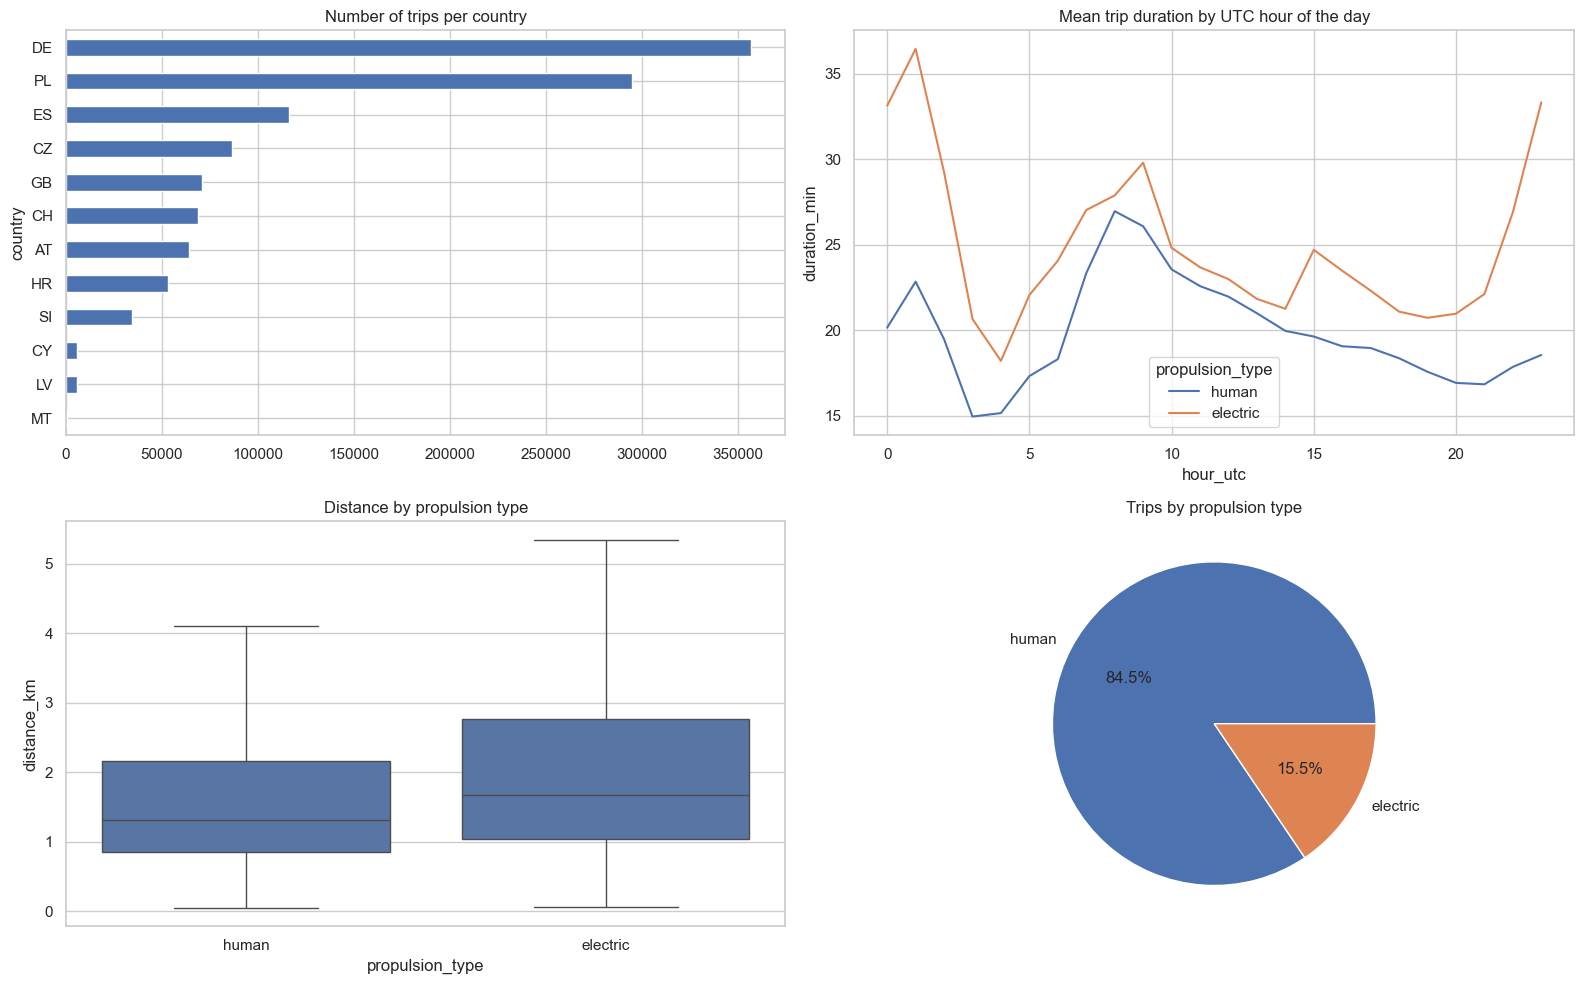

In [282]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
trips_c.groupby("country").size().sort_values().plot(kind="barh", ax=axes[0, 0], title="Number of trips per country")
sns.lineplot(data=trips_c, x="hour_utc", y="duration_min", hue="propulsion_type", estimator="mean", errorbar=None, ax=axes[0, 1])
axes[0, 1].set_title("Mean trip duration by UTC hour of the day")
sns.boxplot(data=trips_c, x="propulsion_type", y="distance_km", showfliers=False, ax=axes[1, 0])
axes[1, 0].set_title("Distance by propulsion type")
trips_c["propulsion_type"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=axes[1, 1], title="Trips by propulsion type")
axes[1, 1].set_ylabel("")
plt.tight_layout()
plt.show()

In [283]:
rto = (trips_c.merge(city[["id", "return_to_official_only"]], left_on="city_id", right_on="id", how="left")
       .groupby("return_to_official_only")
       .agg(trips=("bike_id", "size"), free_start_pct=("free_start", lambda x: x.mean() * 100),
            free_end_pct=("free_end", lambda x: x.mean() * 100)))
display(rto)

,trips,free_start_pct,free_end_pct
return_to_official_only,,,
False,200830,10.633869,15.280586
True,958200,7.079107,9.516281


In [284]:
type_summary = (trips_c.groupby("bike_type_group")
                .agg(trips=("bike_id", "size"), bikes=("bike_id", "nunique"),
                     median_duration_min=("duration_min", "median"), median_distance_km=("distance_km", "median"),
                     electric_share=("propulsion_type", lambda s: (s == "electric").mean()))
                .sort_values("trips", ascending=False))
display(type_summary.round(2))

,trips,bikes,median_duration_min,median_distance_km,electric_share
bike_type_group,,,,,
City bike,971977,22258,12.0,1.31,0.0
E-bike,179996,3202,13.0,1.67,1.0
Bike with child seat,3504,108,18.0,1.40,0.0
Unknown,1298,110,16.0,1.75,0.0
Cargo bike,830,49,16.0,1.01,0.0
Tandem,638,25,18.0,1.32,0.0
Kids bike,622,67,21.0,1.11,0.0
E-cargo bike,95,10,26.0,2.86,1.0
Tricycle,70,4,19.5,1.20,0.0


**Insights**

* Germany and Poland together account for more than half of the trips, and 85% of the trips are on human-powered bikes (15% electric)

* Electric trips are longer in distance and in time.

* In schemes that allow free returns, 10.6% of the trips start and 15.3% end outside a station. Even in schemes that require official returns, 7.1% start and 9.5% end outside a station. The flag `return_to_official_only` therefore indicates a rule, not a guarantee.

## 3. Unsupervised tasks: Bike Trip and Station Profiles

### 3.1 Part A - Clustering Bike Trips

#### Study 1 - Station profiles in the two largest cities

For each of the two cities with the most stations, every station is described by its coordinates (`lat`, `lon`), its activity (`volume_total` = departures + arrivals) and its attractiveness (`ratio_attractivite` = arrivals / departures). After standardisation, a KMeans with 2 clusters groups the stations with similar location and usage.

In [285]:
city_names = city.set_index('id')['name']
city_names

id
220                   Zagreb
431                   Kalisz
199                Innsbruck
519     Siemianowice Śląskie
21                 Karlsruhe
               ...          
853        Sant Just Desvern
856    Sant Boi de Llobregat
831                 Wolsztyn
143                    Tulln
57                 St.Pölten
Name: name, Length: 267, dtype: str

In [286]:
city_stats = (trips_c.groupby('city_id')
              .agg(nb_stations=('station_id_start', 'nunique'),
                   nb_trips=('bike_id', 'size'),
                   share_electric=('propulsion_type', lambda s: (s == 'electric').mean()))
              .nlargest(2, 'nb_stations'))
city_stats.rename(index=city_names).round(3)

,nb_stations,nb_trips,share_electric
city_id,,,
Barcelona,136,6560,1.0
Lublin,122,24784,0.0


We find out that these two cities we found either have only electric bikes for Barcelona or non electric bikes Lublin.

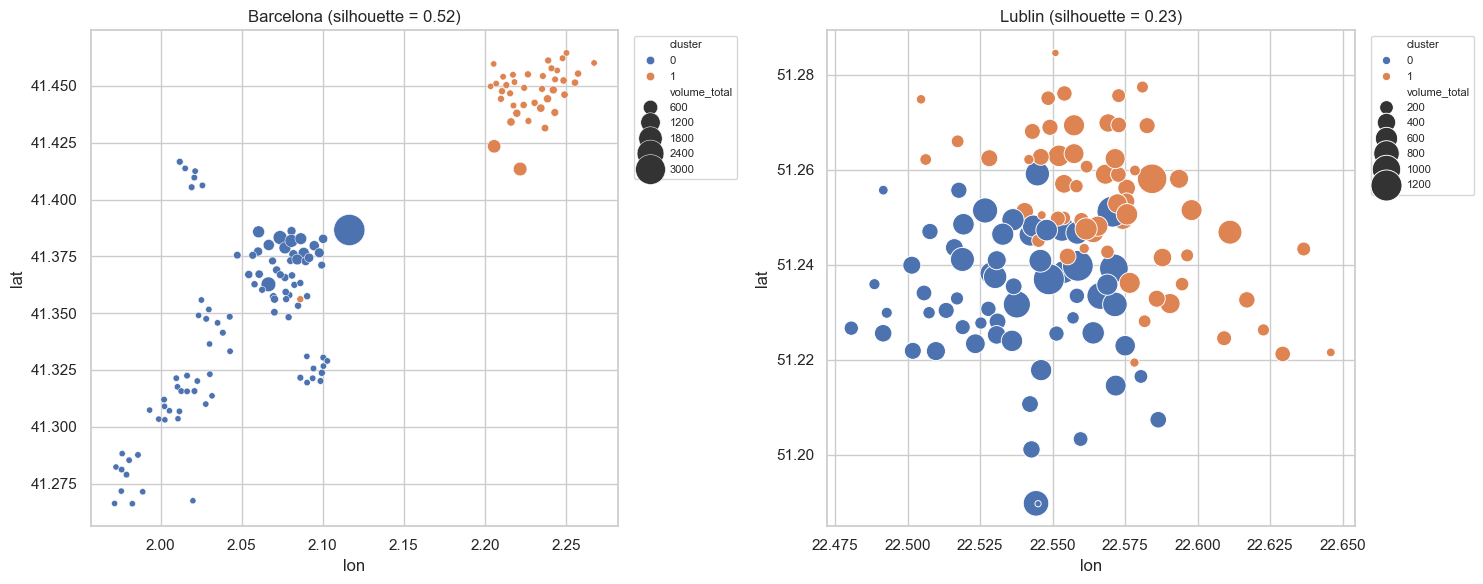

n_stations    lat    lon  mean_volume  mean_ratio
city      cluster                                                   
Barcelona 0                96  41.34   2.05       109.05        3.98
          1                39  41.45   2.23        64.08        7.27
Lublin    0                61  51.23  22.54       481.48        0.96
          1                61  51.25  22.57       314.33        1.17

In [287]:
features_a = ['lat', 'lon', 'volume_total', 'ratio_attractivite']
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
results_a = []

for ax, cid in zip(axes, city_stats.index):
    city_trips = trips_c[trips_c['city_id'] == cid]

    st = city_trips.groupby('station_id_start').agg(
        nb_departs=('bike_id', 'count'), lat=('lat_start', 'median'), lon=('lon_start', 'median'))
    st['nb_arrivals'] = city_trips.groupby('station_id_end').size()
    st = st.dropna()
    st['volume_total'] = st['nb_departs'] + st['nb_arrivals']
    st['ratio_attractivite'] = st['nb_arrivals'] / st['nb_departs']

    X_city = StandardScaler().fit_transform(st[features_a])
    st['cluster'] = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10).fit_predict(X_city)
    st['city'] = city_names[cid]
    results_a.append(st)

    sns.scatterplot(data=st, x='lon', y='lat', hue='cluster', size='volume_total',
                    sizes=(20, 500), ax=ax)
    ax.set_title(f"{city_names[cid]} (silhouette = {silhouette_score(X_city, st['cluster']):.2f})")
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

pd.concat(results_a).groupby(['city', 'cluster']).agg(
    n_stations=('lat', 'size'), lat=('lat', 'mean'), lon=('lon', 'mean'),
    mean_volume=('volume_total', 'mean'), mean_ratio=('ratio_attractivite', 'mean')).round(2)

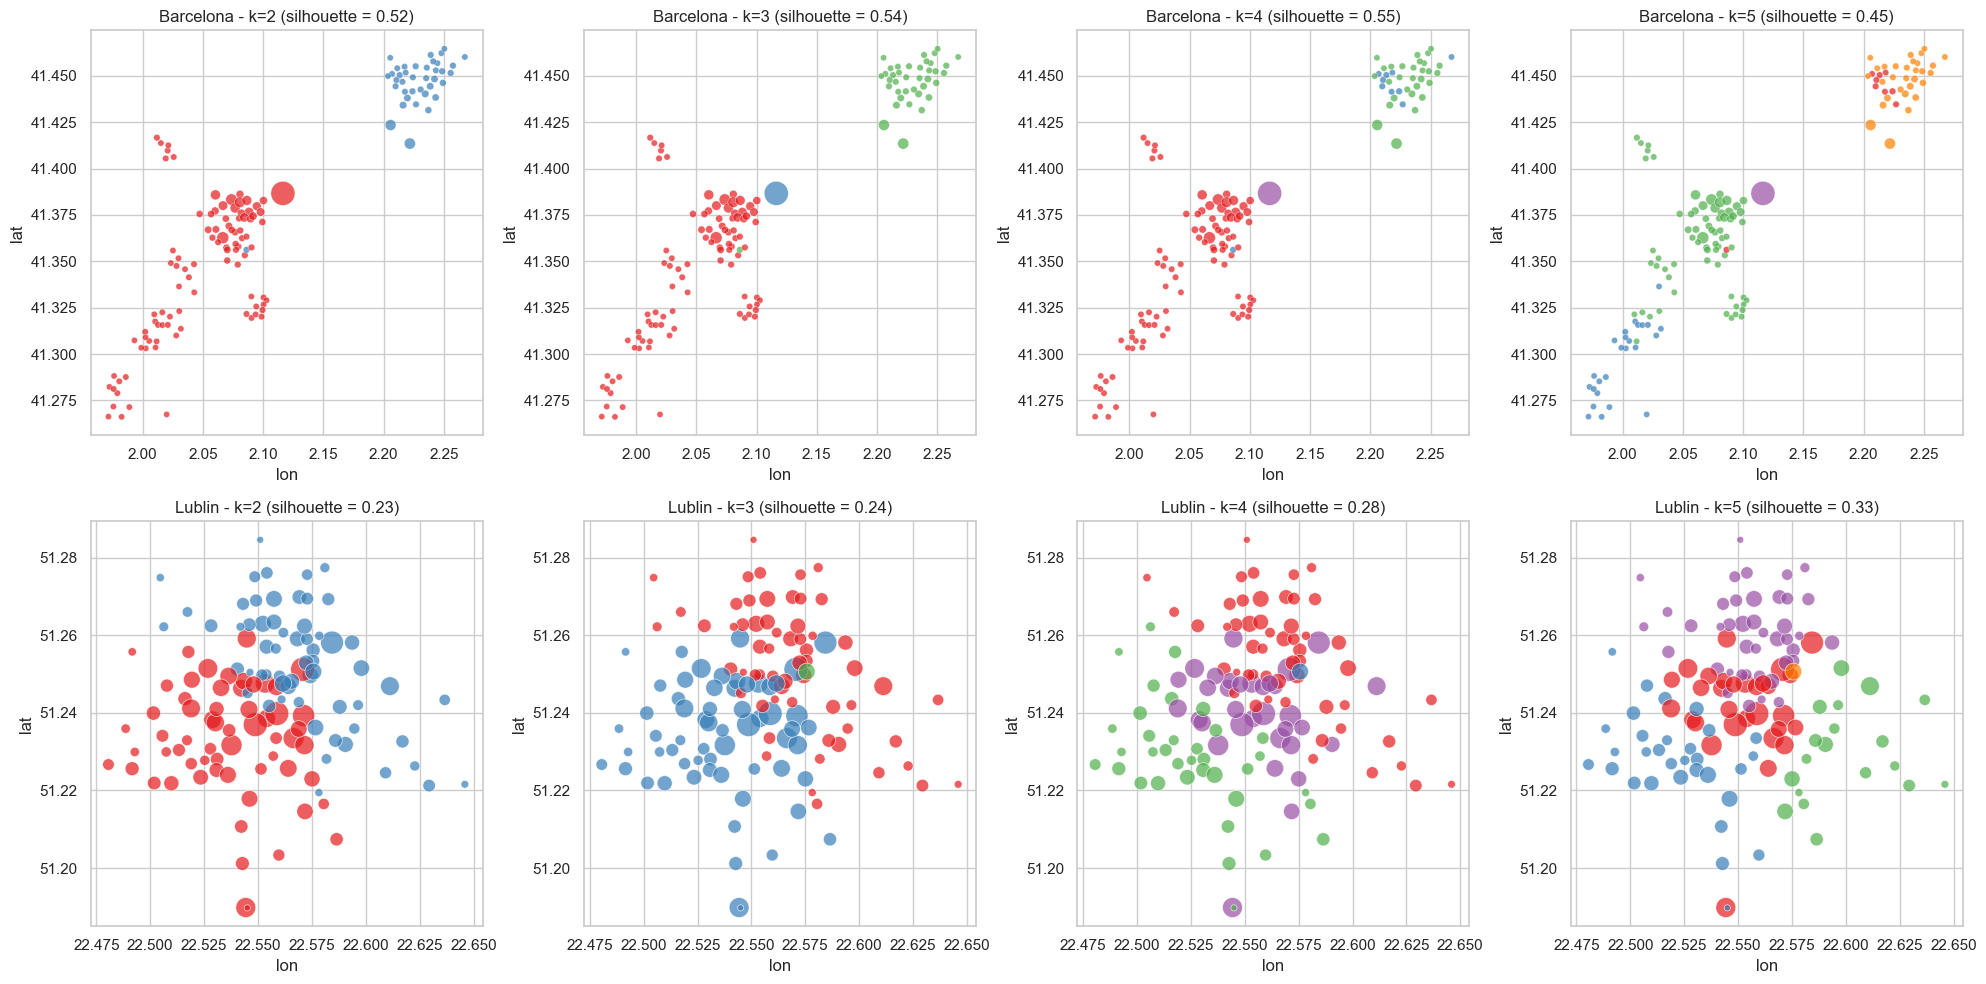

,Barcelona,Lublin
k,,
2,0.521,0.229
3,0.539,0.240
4,0.547,0.279
5,0.446,0.326


In [288]:
ks = [2, 3, 4, 5]
scores_a = {}
fig, axes = plt.subplots(len(results_a), len(ks), figsize=(5 * len(ks), 5 * len(results_a)))

for row, st in zip(axes, results_a):
    city_label = st['city'].iloc[0]
    X_city = StandardScaler().fit_transform(st[features_a])
    for ax, k in zip(row, ks):
        labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(X_city)
        scores_a.setdefault(city_label, {})[k] = silhouette_score(X_city, labels)
        sns.scatterplot(x=st['lon'], y=st['lat'], hue=labels, size=st['volume_total'],
                        sizes=(20, 300), palette='Set1', alpha=0.7, ax=ax, legend=False)
        ax.set_title(f"{city_label} - k={k} (silhouette = {scores_a[city_label][k]:.2f})")

plt.tight_layout()
plt.show()

pd.DataFrame(scores_a).rename_axis('k').round(3)

#### Choice of k and interpretation (k = 2)

**Choice of k.** We tested k = 2 to 5 using the silhouette score, and also looked at the maps. In **Barcelona**, the score is high and stable from k=2 to k=4 (0.52 to 0.55), then drops at k=5 (0.45): the two-zone structure is clear and k=3 or 4 adds almost nothing. In **Lublin**, the score stays low whatever k is (0.23 to 0.33): the stations form a continuum from the center to the periphery, and a larger k only cuts it into slices. We therefore keep **k = 2** for both cities: it is the simplest choice, consistent across the two cities, and interpretable.

**The special case k = 2.** With k=2, KMeans simply splits the stations in two along their direction of greatest variation: it cannot reveal more than two profiles. In Barcelona, the split corresponds to two geographically separate zones, which explains the high score. In Lublin, it only separates a very active zone from a calmer one, without a clear boundary: the low score (0.23) shows that this is a convenient partition, not two truly distinct types of stations.

**Interpretation of the results (k = 2)**

- **Barcelona**: the north-east group has a high arrivals/departures ratio (7.3 on average). It receives far more bikes than it sends out, which looks like a destination zone, i.e. a work or activity area. Departures come mostly from a single hub (about 49% of all departures), which acts as a point of origin. I cannot say that this hub is a residential area: it could also be a depot or a distribution point.

- **Lublin**: the ratio is close to 1 in both groups (0.96 and 1.17). The stations send out as many bikes as they receive, so we can speak neither of a work zone nor of a residential zone. Both groups are mixed zones. The central group is simply more active (mean volume of 481 versus 314).

### 3.2 Part B - Clustering Bike-Sharing Stations

The goal is to detect whether there are residential stations, office stations, employment hubs, highly active stations, etc.

#### Feature engineering on station status

In [289]:
status_fe = status.copy()

# Weekend flag (Monday=0, Sunday=6), from the UTC day of week computed in section 2.3
status_fe['weekend'] = status_fe['day_of_week_utc'] >= 5

In [290]:
# 'capacity' = total number of places in a station
status_fe['capacity'] = status_fe['bikes'] + status_fe['free_racks']
n_before = len(status_fe)
status_fe = status_fe[status_fe['capacity'] > 0]
print("Snapshots removed because the station has no capacity:", n_before - len(status_fe))

Snapshots removed because the station has no capacity: 51565


In [291]:
# fill = rate of bikes in a station
status_fe['fill'] = status_fe['bikes'] / status_fe['capacity']

In [292]:
# empty = 1 if no bike is available to rent, 0 else
status_fe['empty'] = (status_fe['bikes_available_to_rent'] == 0).astype(int)
# full = 1 if the station is full, 0 else
status_fe['full'] = (status_fe['free_racks'] == 0).astype(int)

In [293]:
by_station = status_fe.groupby('station_id')

station_feat = pd.DataFrame({
    'fill_mean': by_station['fill'].mean(),
    'fill_std': by_station['fill'].std(),
    'pct_empty': by_station['empty'].mean(),
    'pct_full': by_station['full'].mean(),
    'pct_maint': by_station['maintenance'].mean(),
})
# fill_std: a high value indicates a station whose stock changes a lot, a low value a stable one

In [294]:
# time slots of the day (UTC hours)
status_fe['slot'] = pd.cut(status_fe['hour_utc'], [-1, 5, 9, 15, 19, 23],
                           labels=['nuit', 'matin', 'midi', 'soir', 'late'])
status_fe

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance,datetime,month,hour_utc,weekday_utc,day_of_week_utc,weekend,capacity,fill,empty,full,slot
0,101896428,1.661530e+09,2,0,2,0,0,0,2022-08-26 16:14:01+00:00,2022-08,16,Friday,4,False,2,1.000000,0,1,soir
1,54643,1.661531e+09,1,0,1,0,0,0,2022-08-26 16:15:01+00:00,2022-08,16,Friday,4,False,1,1.000000,0,1,soir
2,6201611,1.661531e+09,3,0,3,0,0,0,2022-08-26 16:15:01+00:00,2022-08,16,Friday,4,False,3,1.000000,0,1,soir
3,294346,1.661531e+09,8,0,8,0,0,0,2022-08-26 16:15:01+00:00,2022-08,16,Friday,4,False,8,1.000000,0,1,soir
4,781866,1.661531e+09,1,1,0,5,0,0,2022-08-26 16:15:01+00:00,2022-08,16,Friday,4,False,6,0.166667,1,0,soir
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925962,4775132,1.689458e+09,4,0,4,0,0,0,2023-07-15 21:59:01+00:00,2023-07,21,Saturday,5,True,4,1.000000,0,1,late
2925963,51009276,1.689458e+09,7,0,7,3,3,0,2023-07-15 21:59:01+00:00,2023-07,21,Saturday,5,True,10,0.700000,0,0,late
2925964,142144382,1.689458e+09,8,0,8,8,0,0,2023-07-15 21:59:01+00:00,2023-07,21,Saturday,5,True,16,0.500000,0,0,late
2925965,142141158,1.689458e+09,13,0,13,15,0,0,2023-07-15 21:59:01+00:00,2023-07,21,Saturday,5,True,28,0.464286,0,0,late


In [295]:
slots = status_fe.pivot_table(index='station_id', columns='slot', values='fill', aggfunc='mean', observed=False)
slots

slot,nuit,matin,midi,soir,late
station_id,,,,,
94,NaN,1.0,1.0000,1.000000,NaN
522,1.0,1.0,1.0000,1.000000,1.000000
556,1.0,1.0,1.0000,1.000000,1.000000
568,1.0,1.0,1.0000,1.000000,1.000000
572,NaN,1.0,1.0000,1.000000,NaN
...,...,...,...,...,...
209690395,NaN,1.0,1.0000,1.000000,1.000000
209691495,1.0,NaN,NaN,1.000000,NaN
214585310,1.0,1.0,1.0000,1.000000,1.000000


In [296]:
station_feat = station_feat.join(slots.add_prefix('fill_'))
station_feat

,fill_mean,fill_std,pct_empty,pct_full,pct_maint,fill_nuit,fill_matin,fill_midi,fill_soir,fill_late
station_id,,,,,,,,,,
94,1.000000,0.000000,0.022989,1.0,0.0,NaN,1.0,1.0000,1.000000,NaN
522,1.000000,0.000000,0.000000,1.0,0.0,1.0,1.0,1.0000,1.000000,1.000000
556,1.000000,0.000000,0.000000,1.0,0.0,1.0,1.0,1.0000,1.000000,1.000000
568,1.000000,0.000000,0.024590,1.0,0.0,1.0,1.0,1.0000,1.000000,1.000000
572,1.000000,0.000000,0.000000,1.0,0.0,NaN,1.0,1.0000,1.000000,NaN
...,...,...,...,...,...,...,...,...,...,...
209690395,1.000000,0.000000,0.000000,1.0,0.0,NaN,1.0,1.0000,1.000000,1.000000
209691495,1.000000,0.000000,0.000000,1.0,0.0,1.0,NaN,NaN,1.000000,NaN
214585310,1.000000,0.000000,0.000000,1.0,0.0,1.0,1.0,1.0000,1.000000,1.000000


In [297]:
# Week vs weekend: mean fill rate of each group
weekend_fill = status_fe.groupby(['station_id', 'weekend'])['fill'].mean().unstack()
weekend_fill

weekend,False,True
station_id,,
94,1.000000,1.00
522,1.000000,1.00
556,1.000000,1.00
568,1.000000,1.00
572,1.000000,1.00
...,...,...
209690395,1.000000,1.00
209691495,1.000000,1.00
214585310,1.000000,1.00


In [298]:
# if diff_we > 0, the station is more in demand during the weekend than during the rest of the week
# if diff_we < 0, the station is more in demand on weekdays
# else, similar usage all week long
station_feat['diff_we'] = weekend_fill[True] - weekend_fill[False]
station_feat

,fill_mean,fill_std,pct_empty,pct_full,pct_maint,fill_nuit,fill_matin,fill_midi,fill_soir,fill_late,diff_we
station_id,,,,,,,,,,,
94,1.000000,0.000000,0.022989,1.0,0.0,NaN,1.0,1.0000,1.000000,NaN,0.000000
522,1.000000,0.000000,0.000000,1.0,0.0,1.0,1.0,1.0000,1.000000,1.000000,0.000000
556,1.000000,0.000000,0.000000,1.0,0.0,1.0,1.0,1.0000,1.000000,1.000000,0.000000
568,1.000000,0.000000,0.024590,1.0,0.0,1.0,1.0,1.0000,1.000000,1.000000,0.000000
572,1.000000,0.000000,0.000000,1.0,0.0,NaN,1.0,1.0000,1.000000,NaN,0.000000
...,...,...,...,...,...,...,...,...,...,...,...
209690395,1.000000,0.000000,0.000000,1.0,0.0,NaN,1.0,1.0000,1.000000,1.000000,0.000000
209691495,1.000000,0.000000,0.000000,1.0,0.0,1.0,NaN,NaN,1.000000,NaN,0.000000
214585310,1.000000,0.000000,0.000000,1.0,0.0,1.0,1.0,1.0000,1.000000,1.000000,0.000000


In [ ]:
station_feat = station_feat.join(STATION_INFO[['bike_racks', 'lon', 'lat']])
#reduce the mean and std using log(x+1)
#log1p can handle null values. And, the distribution  of "bike_racks" is asymetric: alot of meadum-sized station and few very large ones.
# so we use log1p to bring the distribution closer to a more symmetrical form. 
station_feat['bike_racks'] = np.log1p(station_feat['bike_racks'])

#### Choice of k

In [300]:
# lon and lat are not used for the clustering (only to draw the clusters)
feat_cols = [c for c in station_feat.columns if c not in ['lon', 'lat']]
print(feat_cols)
X_stations = StandardScaler().fit_transform(station_feat[feat_cols].dropna())

for k in range(2, 9):
    # n_init=10: the algorithm restarts 10 times with different centers
    km = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(X_stations)
    # km.inertia_: sum of the squared distances between each station and the center of its cluster
    print(k, silhouette_score(X_stations, km.labels_), km.inertia_)

['fill_mean', 'fill_std', 'pct_empty', 'pct_full', 'pct_maint', 'fill_nuit', 'fill_matin', 'fill_midi', 'fill_soir', 'fill_late', 'diff_we', 'bike_racks']
2 0.6023098318211103 12181.45892998198
3 0.4964161602076961 9517.598963300225
4 0.519859294223968 7405.995035138297
5 0.49407809254548296 6345.672617710813
6 0.48762449145535275 5555.679037860858
7 0.4899440589467564 4974.925182442202
8 0.4940829806056694 4577.977121396988


#### Final clustering (k = 4)

In [301]:
station_feat_ok = station_feat[feat_cols].dropna().copy()
km_stations = KMeans(4, n_init=10, random_state=RANDOM_STATE).fit(X_stations)
station_feat_ok['cluster'] = km_stations.labels_
# Add lon and lat to draw the clusters
station_feat_ok = station_feat_ok.join(station_feat[['lon', 'lat']])
print(station_feat_ok['cluster'].value_counts().sort_index())

cluster
0     610
1    1071
2     840
3      68
Name: count, dtype: int64


In [302]:
# Description of each cluster
cluster_profile = station_feat_ok.groupby('cluster')[feat_cols].mean().round(2)
print(cluster_profile.T)

cluster        0     1     2     3
fill_mean   0.34  1.00  0.62  0.65
fill_std    0.21  0.00  0.24  0.17
pct_empty   0.10  0.02  0.02  0.04
pct_full    0.02  1.00  0.17  0.35
pct_maint   0.00  0.00  0.00  0.99
fill_nuit   0.35  1.00  0.64  0.65
fill_matin  0.35  1.00  0.62  0.65
fill_midi   0.34  1.00  0.62  0.65
fill_soir   0.34  1.00  0.63  0.64
fill_late   0.34  1.00  0.63  0.65
diff_we    -0.00 -0.00 -0.00 -0.00
bike_racks  2.39  0.05  2.29  1.70


- **Cluster 0**: fill_mean = 0.34, active cluster, bike_racks = 2.39 (nearly 10 docks)
- **Cluster 1**: fill_mean = 1, always full, bike_racks = 0.05 (capacity too low)
- **Cluster 2**: fill_mean = 0.62, active cluster, pct_empty = 0.02 (rarely empty)
- **Cluster 3**: pct_maint = 0.99, out-of-service cluster

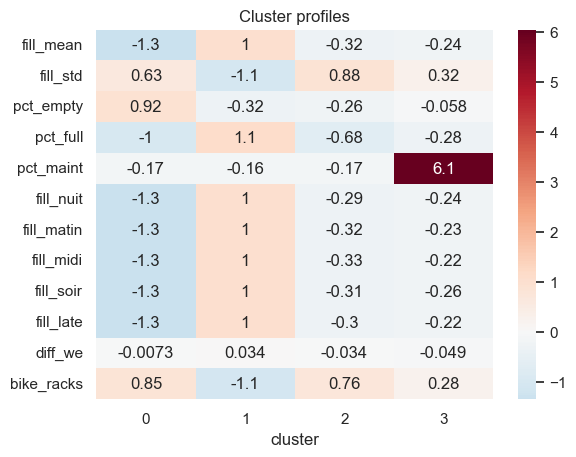

In [303]:
# Standardized version
cluster_profile_z = (pd.DataFrame(X_stations, columns=feat_cols, index=station_feat_ok.index)
                     .groupby(station_feat_ok['cluster']).mean())
sns.heatmap(cluster_profile_z.T, annot=True, cmap='RdBu_r', center=0)
plt.title("Cluster profiles")
plt.show()

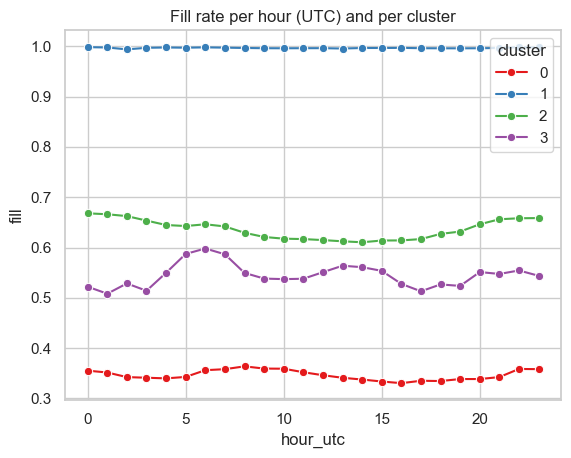

In [304]:
status_fe_cl = status_fe.merge(station_feat_ok[['cluster']], left_on='station_id', right_index=True)
hourly_fill = status_fe_cl.groupby(['cluster', 'hour_utc'])['fill'].mean().reset_index()
sns.lineplot(data=hourly_fill, x='hour_utc', y='fill', hue='cluster', palette="Set1", marker='o')
plt.title("Fill rate per hour (UTC) and per cluster")
plt.show()

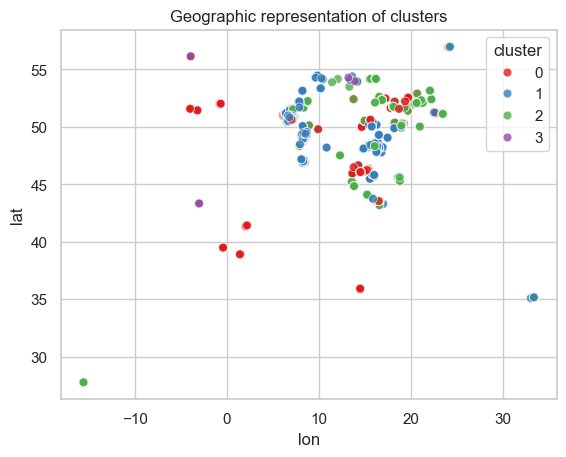

In [305]:
sns.scatterplot(data=station_feat_ok, x='lon', y='lat', hue='cluster', palette='Set1', s=40, alpha=0.8)
plt.title("Geographic representation of clusters")
plt.show()

#### Stability check: KMeans vs Ward

In [306]:
ward = AgglomerativeClustering(4).fit_predict(X_stations)
print("ARI KMeans vs ward :", adjusted_rand_score(km_stations.labels_, ward))
# ARI close to 1 means both methods find the same clustering ==> stable clustering

ARI KMeans vs ward : 0.8581429907886912
